# Physics-Informed Self-Supervised Porosity Inversion
## RW-PINN with OBN 3D Seismic Data

**Reference:** *Direct Estimation of Porosity from Seismic Data using RW-PINN*  
Vashisth & Mukerji, Stanford University

**Method: Fully Self-Supervised RW-PINN**
*(Horizon constraint removed: time range 960-1667ms mismatches seismic 985-1700ms, cannot build reliable mask)*

---

### Network Framework (Paper Figure 1)
```
Input seismic trace
  -> 1D CNN Encoder (5 conv, 32->64->128->256->D, He init, Dropout 30%)
  -> tanh -> linear -> porosity phi in [0.05, 0.35]
  -> Wyllie (rock physics decoder) -> Vp, rho
  -> AI -> RC -> Wavelet convolution
  -> Synthetic trace
  -> NRMS loss (self-supervised signal)
```

### Total Loss (Eq.1, Self-Supervised)
$$L_{total} = L_{NRMS\_seismic}$$

### Data
| File | Use |
|------|------|
| `OBN_NEW INTERVAL` | Main volume — 1,353,053 traces x 716, 985-1700 ms |

*(No horizon files used)*
### Normalization Protocol in This Bridge Version

Real seismic traces are percentile-clipped and mapped to `[0, 1]`. The wave-physics
decoder then maps the synthetic trace to the same comparison domain using one
scalar min-max value pair over the whole forward batch:

$$S_{syn}^{BMM}=\frac{S_{syn}-\min_{batch}(S_{syn})}{\max_{batch}(S_{syn})-\min_{batch}(S_{syn})+\epsilon}$$

This is the protocol used by the earlier v2/v3 experiments. It is not per-trace
normalization and should be reported as a batch-minmax bridge baseline.


## Setup — Install Dependencies

In [1]:
# ========================================================================
# RW-PINN Porosity Inversion Project
# Purpose: Reservoir porosity prediction using seismic data and PINN (Physics-Informed Neural Network)
# Framework: PyTorch
# ========================================================================

# Run once — restart kernel after if needed
import sys
!{sys.executable} -m pip install segyio torch numpy scipy matplotlib pandas tqdm scikit-learn --quiet
!find / -name "OBN_NEW*" -maxdepth 4 2>/dev/null

/root/autodl-tmp/OBN_NEW.zip
/root/autodl-tmp/OBN_NEW
/root/autodl-tmp/OBN_NEW/OBN_NEW INTERVAL


## Configuration — Module Imports & Global Parameters

In [2]:
# ==========================================================================
# RW-PINN Porosity Inversion — Fully Self-Supervised Version
# Framework: PyTorch | Rock Physics: Wyllie Time-Average Equation
# ==========================================================================

import numpy as np
import os
import sys
import time
import gc
import matplotlib
if not os.environ.get('DISPLAY') and 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as path_effects
import pandas as pd
from pathlib import Path
from scipy.signal import correlate, windows
import warnings
warnings.filterwarnings('ignore')
# Helps reduce CUDA memory fragmentation on AutoDL/Jupyter.
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import torch

# RTX 4090 performance switches. These do not change the model architecture.
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True
try:
    torch.set_float32_matmul_precision('high')
except Exception:
    pass
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
import segyio
from tqdm.notebook import tqdm

# ── Reproducibility ───────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── File Paths (modify based on actual location) ────────────────
SEGY_INTERVAL = r'/root/autodl-tmp/OBN_NEW/OBN_NEW INTERVAL'
# AutoDL/headless-safe plotting and paper-output helpers
if Path('/root/autodl-tmp').exists():
    OUTPUT_DIR = Path('/root/autodl-tmp/rw_pinn_output')
else:
    OUTPUT_DIR = Path('rw_pinn_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Output directory: {OUTPUT_DIR.resolve()}')

IEEE_RC = {
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'Liberation Serif', 'DejaVu Serif'],
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.02,
    'axes.linewidth': 0.6,
    'lines.linewidth': 1.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
}

def apply_ieee_style():
    plt.rcParams.update(IEEE_RC)

def save_ieee_figure(fig, filename, pdf=True):
    out = OUTPUT_DIR / filename
    fig.savefig(out, dpi=600, bbox_inches='tight', pad_inches=0.02)
    if pdf:
        fig.savefig(out.with_suffix('.pdf'), bbox_inches='tight', pad_inches=0.02)
    print(f'Saved figure: {out}')

apply_ieee_style()

# ── Hardware Configuration ───────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')
if DEVICE == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# ── Wyllie Rock Physics Parameters ────────────────────────────────
VF      = 1500.0   # m/s  pore fluid velocity (brine)
VM      = 5500.0   # m/s  rock matrix velocity (sandstone)
RHO_M   = 2650.0   # kg/m3  matrix density
RHO_F   = 1040.0   # kg/m3  fluid density

# ── Porosity Range ──────────────────────────────────────────────
PHI_MIN = 0.05
PHI_MAX = 0.35

# ── Training Hyperparameters ───────────────────────────────────────
BATCH_SIZE   = 256     # RTX 4090 fast default; keep 256 for BMM comparability with old runs
EPOCHS       = 200
LR           = 1e-4
VAL_FRAC     = 0.05    # 5% validation set is sufficient
DROPOUT_RATE = 0.30
NUM_WORKERS  = 0       # AutoDL/Jupyter-safe: avoids worker memory duplication and kernel kills
PIN_MEMORY   = False   # safer with large in-memory seismic arrays
ENABLE_TORCH_COMPILE = True   # set False if first epoch compile memory is unstable
INFERENCE_BATCH_SIZE = 512
VOLUME_DTYPE = np.float16  # halves 3D porosity volume RAM use; saved values remain adequate for QC
ENABLE_GPU_RESIDENT_DATA = True  # keep seismic training tensor on the 4090 when VRAM allows
GPU_DATA_FRACTION_LIMIT = 0.45   # only use GPU-resident data if it uses <45% free VRAM
RICKER_FREQ  = 40.0    # Hz  fallback wavelet frequency

print('Configuration loaded.')
print(f'Rock Physics: Wyllie Vf={VF} Vm={VM}')
print(f'Porosity range: [{PHI_MIN}, {PHI_MAX}]')


Output directory: /root/autodl-tmp/rw_pinn_output
Device: cuda
GPU: NVIDIA GeForce RTX 4090
Configuration loaded.
Rock Physics: Wyllie Vf=1500.0 Vm=5500.0
Porosity range: [0.05, 0.35]


## Step 1 — Load SEG-Y & Reconstruct 3D Seismic Volume

In [3]:
# ========================================================================
# RW-PINN Porosity Inversion Project
# Purpose: Reservoir porosity prediction using seismic data and PINN
# Framework: PyTorch
# ========================================================================

# load_segy_cube
def load_segy_cube(path: str):

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f'SEG-Y not found: {path}')

    print(f'Opening {path.name} ...')

    try:

        with segyio.open(str(path), ignore_geometry=False) as f:

            dt_ms = segyio.tools.dt(f) / 1000.0

            cube = segyio.tools.cube(f)

            # ==================================================
            # REAL seismic time axis
            # ==================================================
            t_axis = np.array(f.samples)

            inlines = f.ilines
            xlines  = f.xlines

        print(f'  Structured read: cube shape = {cube.shape}  dt = {dt_ms:.3f} ms')

    except Exception as e:

        print(f'  Structured read failed ({e}), falling back to flat read ...')

        with segyio.open(str(path), ignore_geometry=True) as f:

            dt_ms = segyio.tools.dt(f) / 1000.0

            # ==================================================
            # REAL seismic time axis
            # ==================================================
            t_axis = np.array(f.samples)

            traces = np.array([t.copy() for t in f.trace], dtype=np.float32)

            iline_h = f.attributes(segyio.TraceField.INLINE_3D)[:]
            xline_h = f.attributes(segyio.TraceField.CROSSLINE_3D)[:]

        inlines = np.unique(iline_h)
        xlines  = np.unique(xline_h)

        n_il, n_xl, n_t = len(inlines), len(xlines), traces.shape[1]

        cube = np.full((n_il, n_xl, n_t), np.nan, dtype=np.float32)

        il_idx = {v: i for i, v in enumerate(inlines)}
        xl_idx = {v: i for i, v in enumerate(xlines)}

        for k in range(len(traces)):

            i = il_idx.get(iline_h[k])
            j = xl_idx.get(xline_h[k])

            if i is not None and j is not None:
                cube[i, j, :] = traces[k]

        print(f'  Flat read: cube shape = {cube.shape}  dt = {dt_ms:.3f} ms')

    return (
        cube,
        np.array(inlines),
        np.array(xlines),
        dt_ms,
        t_axis
    )


# ── Load main seismic volume ───────────────────────────────────────────────────
cube, inlines, xlines, dt_ms, t_axis = load_segy_cube(SEGY_INTERVAL)

n_il, n_xl, n_t = cube.shape

print(f'\nVolume: {n_il} inlines × {n_xl} xlines × {n_t} samples')

print(f'Inline range  : {inlines[0]} – {inlines[-1]}')
print(f'Xline range   : {xlines[0]} – {xlines[-1]}')

print(f'Time range    : {t_axis[0]:.1f} – {t_axis[-1]:.1f} ms')

print(f'Memory        : {cube.nbytes / 1e9:.2f} GB')

Opening OBN_NEW INTERVAL ...
  Structured read: cube shape = (1261, 1073, 716)  dt = 1.000 ms

Volume: 1261 inlines × 1073 xlines × 716 samples
Inline range  : 1659 – 2919
Xline range   : 124 – 1196
Time range    : 985.0 – 1700.0 ms
Memory        : 3.88 GB


## Step 2 — Seismic Data Quick QC

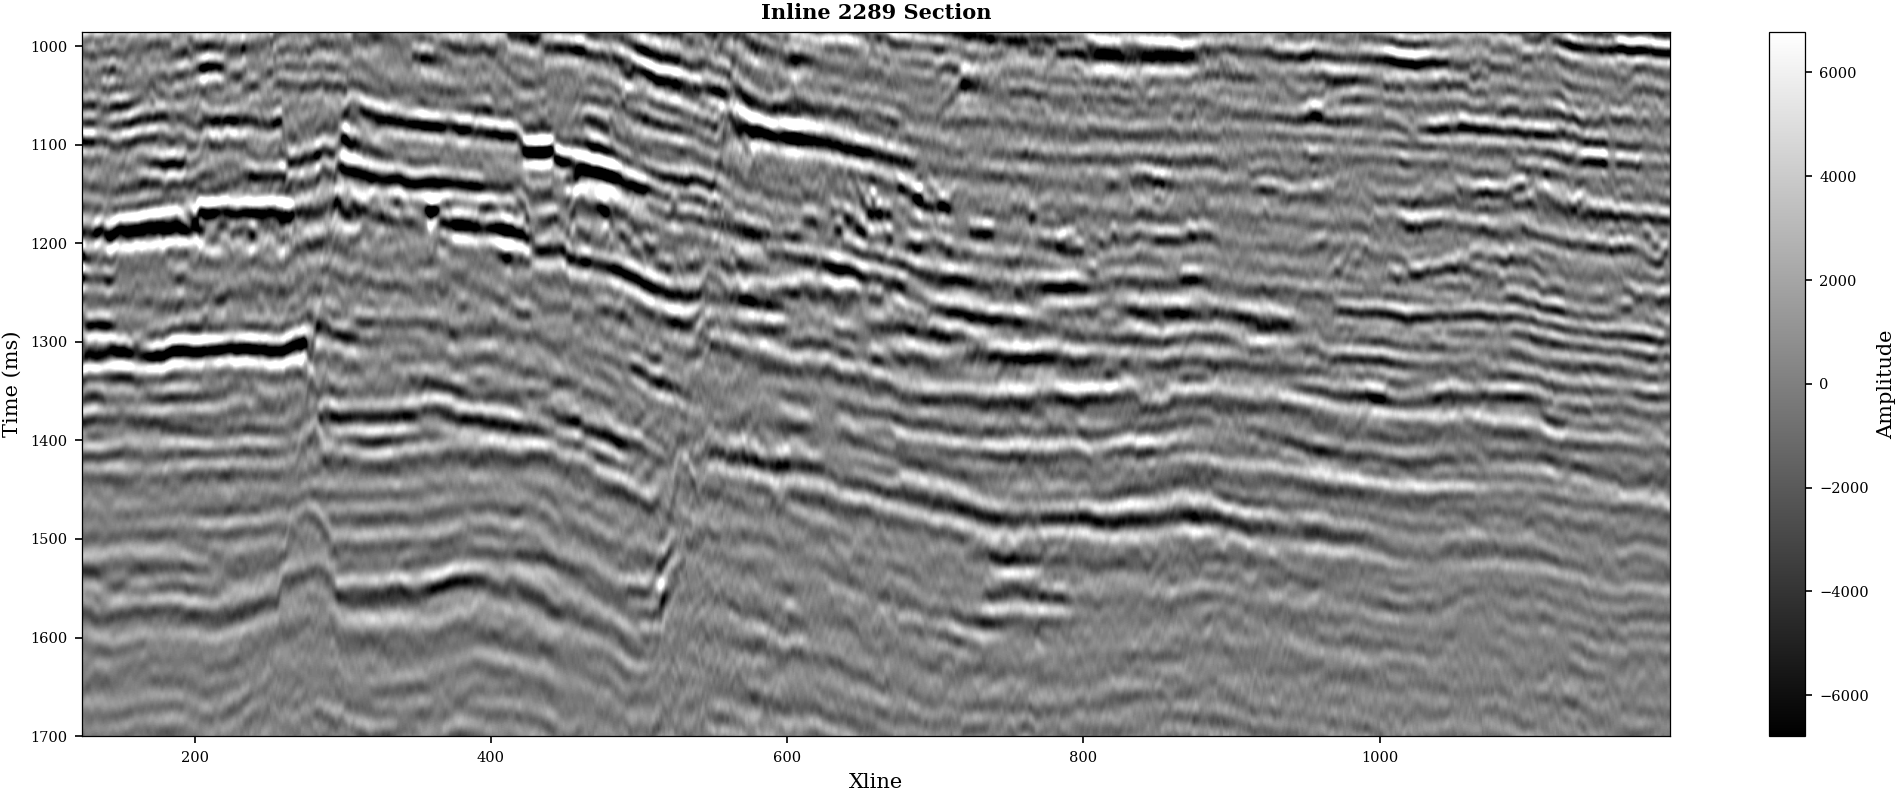

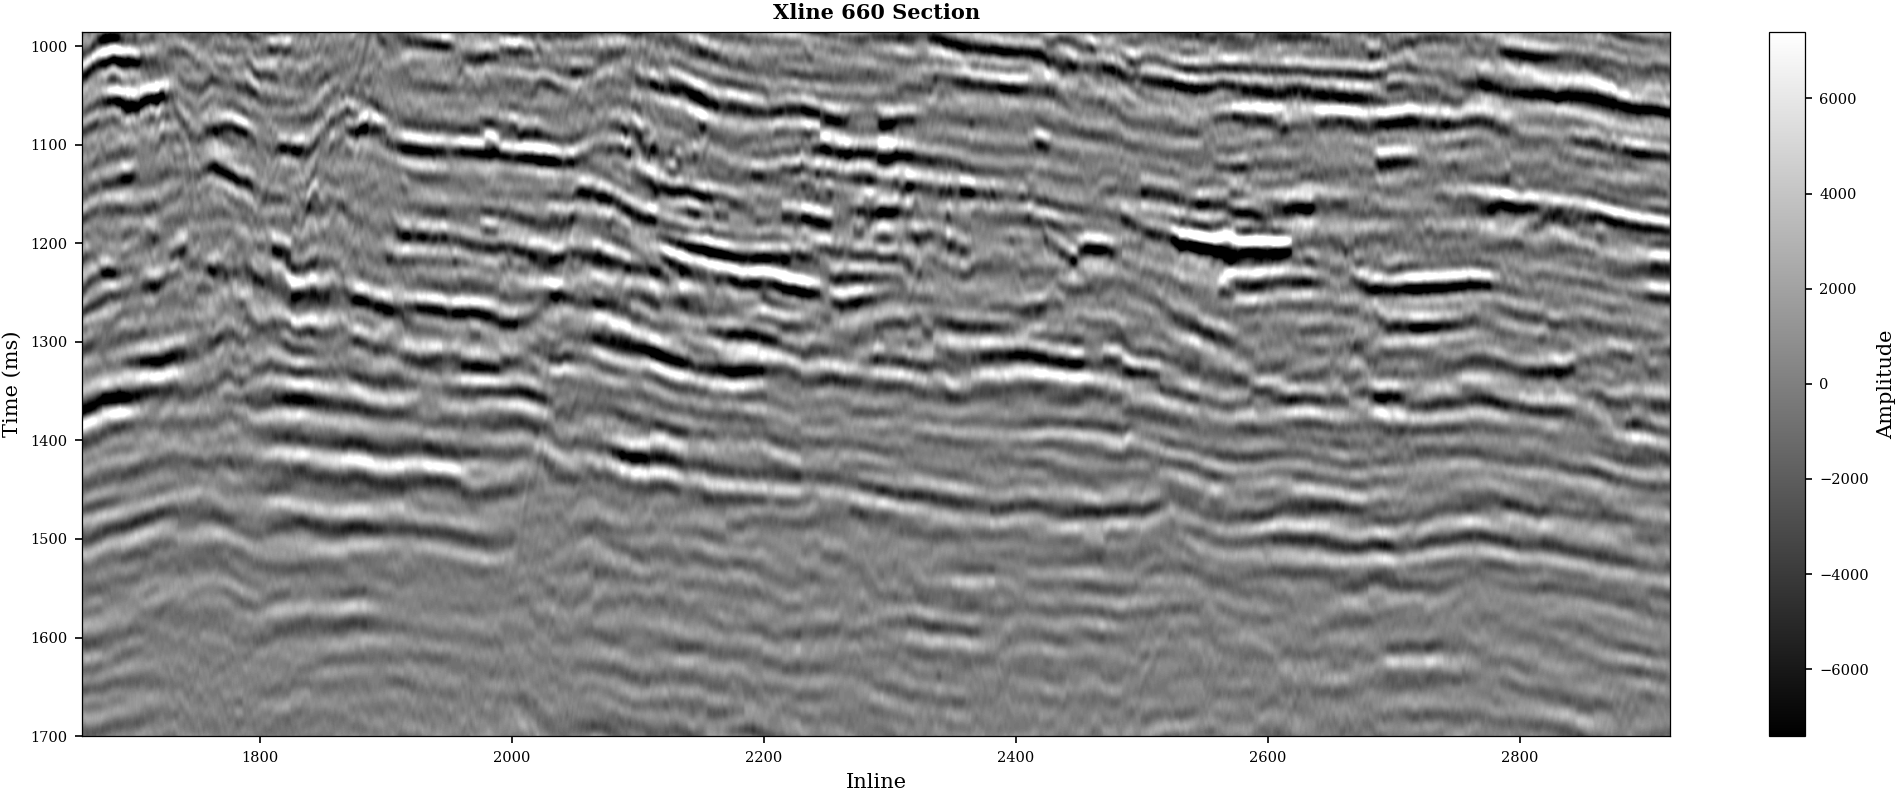

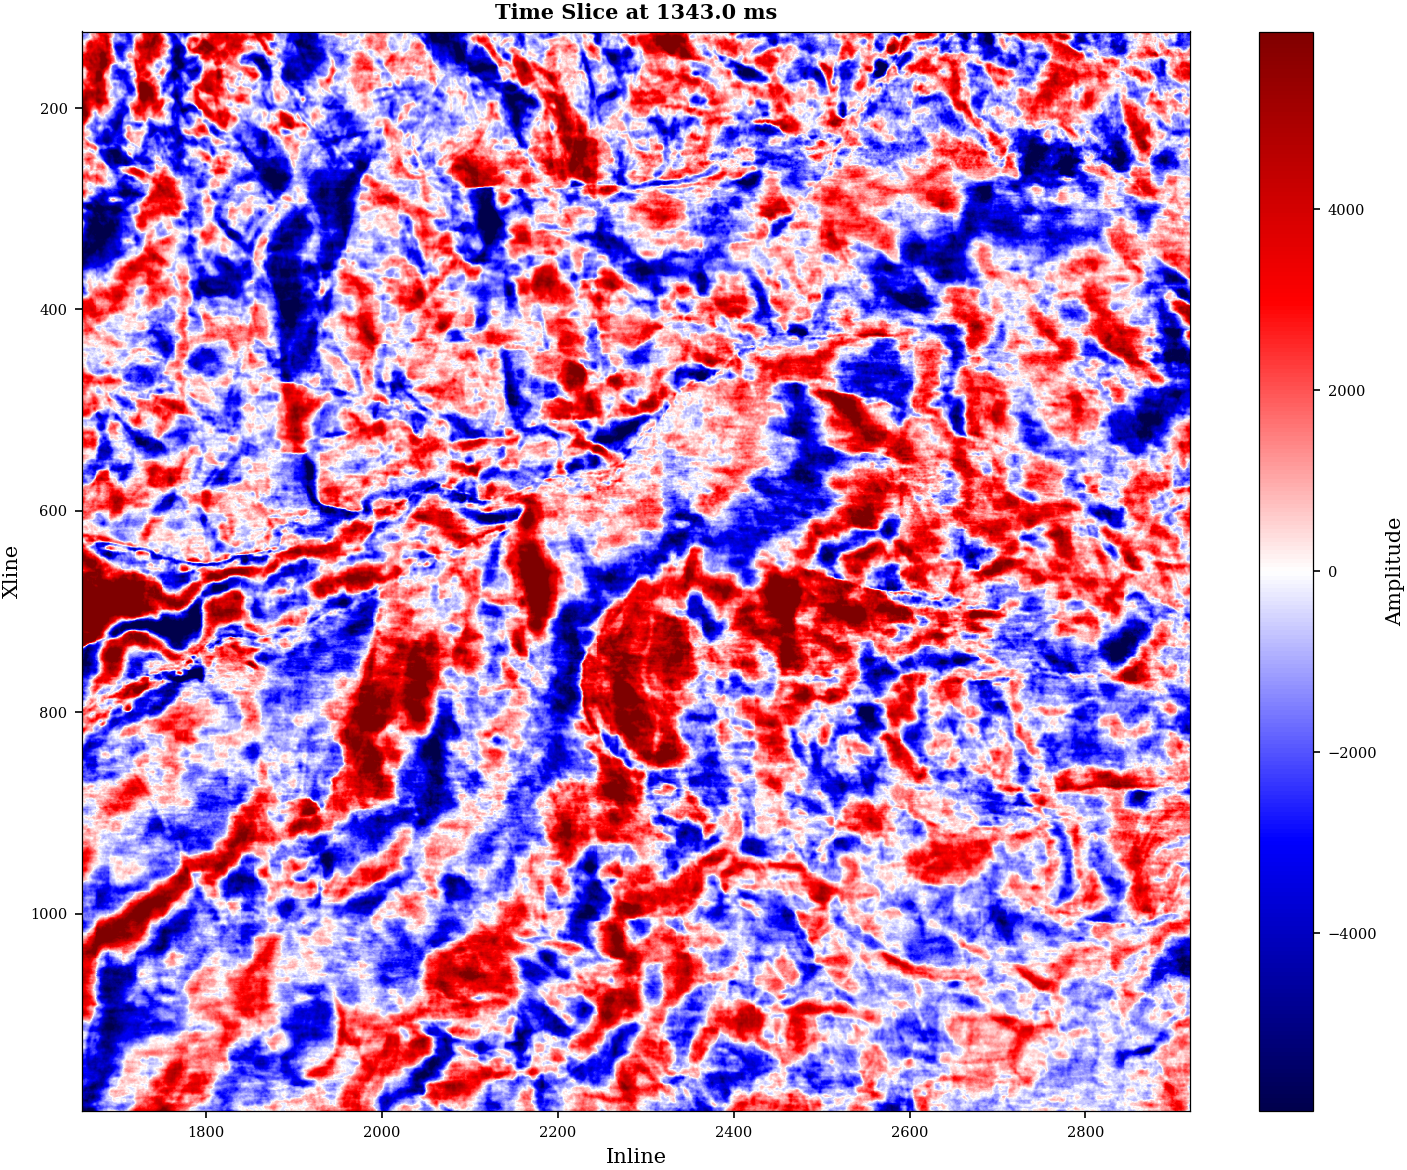

In [4]:
# ========================================================================
# RW-PINN Porosity Inversion Project
# Purpose: Reservoir porosity prediction using seismic data and PINN
# Framework: PyTorch
# ========================================================================
# ========================================================================
# plot_2d_seismic_section (publication-quality style)
# ========================================================================
def plot_seismic_section(data_2d, x_axis, xlabel, title, cmap='gray', perc=98):
    """
    Plot 2D seismic section
    :param data_2d: 2D array data
    :param x_axis: x-axis array (inlines or xlines)
    :param xlabel: x-axis label ('Inline' or 'Xline')
    :param title: plot title
    :param cmap: colormap, 'gray' for best event contrast
    """
    vmax = np.nanpercentile(np.abs(data_2d), perc)
    fig, ax = plt.subplots(figsize=(14, 5.5)) # slightly taller for better layout
    
    # Fix: use passed cmap parameter instead of hardcoded 'gray'
    im = ax.imshow(data_2d.T, aspect='auto', cmap=cmap,
                   vmin=-vmax, vmax=vmax,
                   extent=[x_axis[0], x_axis[-1], t_axis[-1], t_axis[0]])
    
    # Colorbar style optimization
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Amplitude', fontsize=10)
    
    # Axis and title style optimization
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel('Time (ms)', fontsize=10)
    ax.set_title(title, fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

# ========================================================================
# Start plotting sections and slices
# ========================================================================
# Get midpoint index
mid_il = n_il // 2
mid_xl = n_xl // 2
mid_t = n_t // 2

# 1. Inline section (fixed Inline, X-axis spans Xlines)
plot_seismic_section(cube[mid_il, :, :], 
                     x_axis=xlines, 
                     xlabel='Xline', 
                     title=f'Inline {inlines[mid_il]} Section',
                     cmap='gray')

# 2. Xline section (fixed Xline, X-axis spans Inlines)
plot_seismic_section(cube[:, mid_xl, :], 
                     x_axis=inlines, 
                     xlabel='Inline', 
                     title=f'Xline {xlines[mid_xl]} Section',
                     cmap='gray')

# 3. Time slice at middle (horizontal time slice)
# For plan-view slices, aspect ratio ~1:1 or match survey dims
fig, ax = plt.subplots(figsize=(10, 8)) 
vmax_t = np.nanpercentile(np.abs(cube[:, :, mid_t]), 98)

# Fix: removed duplicate imshow call.
# Slice colormap: 'RdBu' (red-white-blue) or keep 'seismic'
im_t = ax.imshow(cube[:, :, mid_t].T, aspect='auto', cmap='seismic',
                 vmin=-vmax_t, vmax=vmax_t,
                 extent=[inlines[0], inlines[-1], xlines[-1], xlines[0]])

# Slice plot axes are Inline and Xline
ax.set_xlabel('Inline', fontsize=10)
ax.set_ylabel('Xline', fontsize=10)
ax.set_title(f'Time Slice at {t_axis[mid_t]:.1f} ms', fontsize=10, fontweight='bold')

cbar_t = plt.colorbar(im_t, ax=ax)
cbar_t.set_label('Amplitude', fontsize=10)

plt.tight_layout()
plt.show()


In [5]:
# ==========================================================================
# Horizon disabled — using all 716 samples for self-supervised training
# ==========================================================================

hrz_top    = None
hrz_bottom = None
HORIZONS_AVAILABLE = False
idx_top    = None
idx_bottom = None

print('Horizon disabled. Using all 716 samples for self-supervised training.')
print(f'Seismic data time range: {t_axis[0]:.1f} - {t_axis[-1]:.1f} ms')

Horizon disabled. Using all 716 samples for self-supervised training.
Seismic data time range: 985.0 - 1700.0 ms


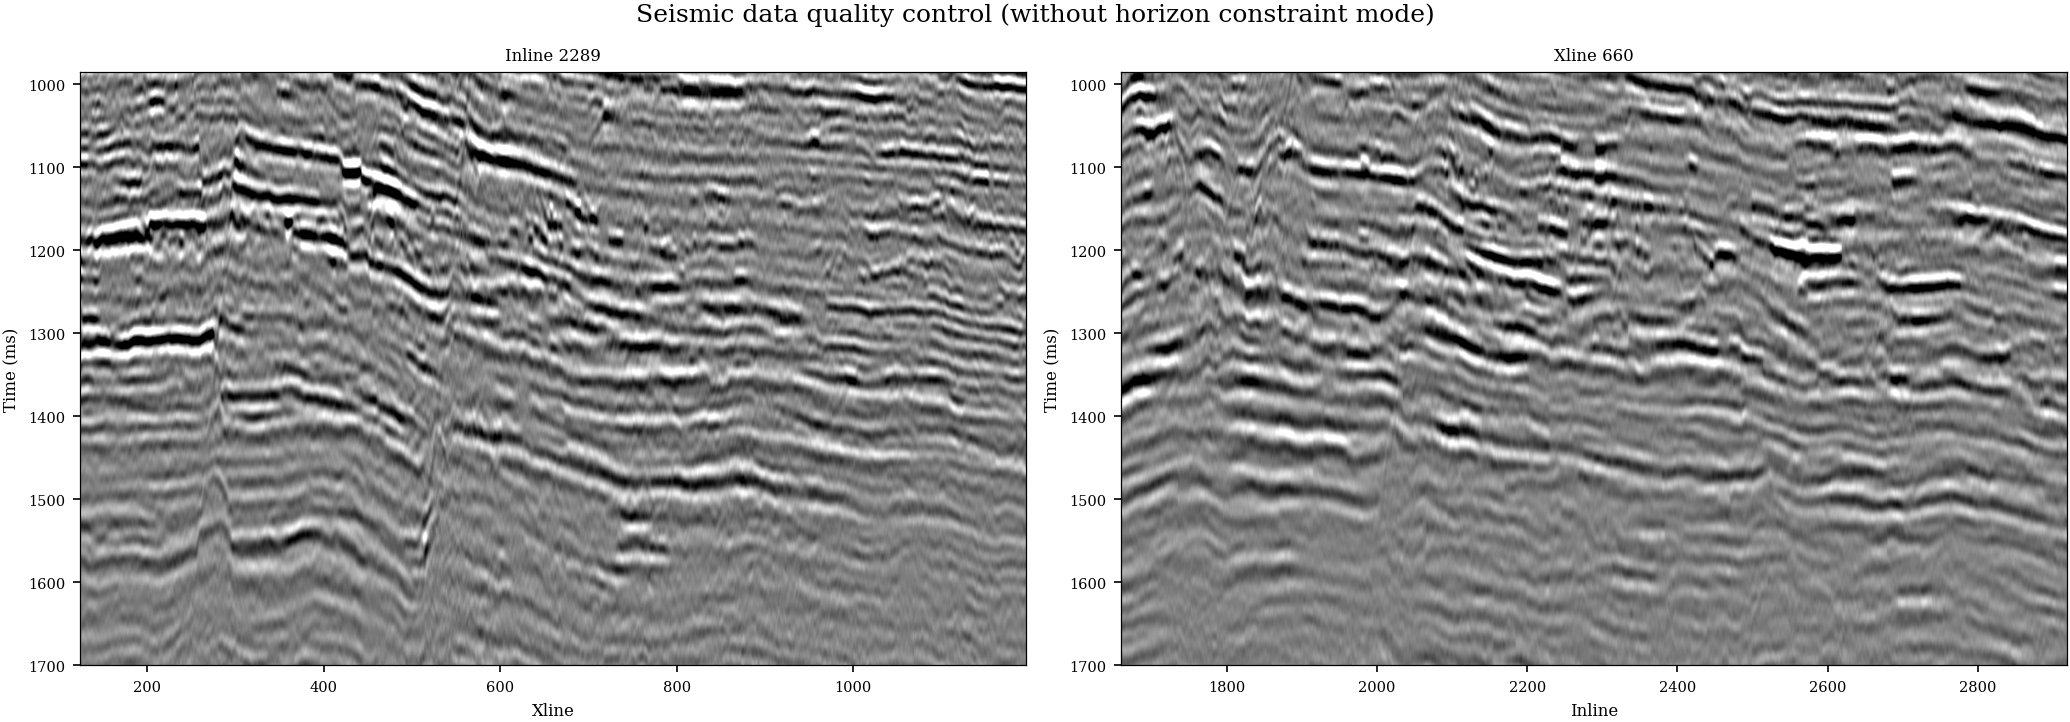

Note: Horizon disabled. Showing seismic section only.


In [6]:
# ==========================================================================
# [Modified] Horizon QC -> seismic section only, no horizon overlay
# ==========================================================================

mid_il = n_il // 2
mid_xl = n_xl // 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Seismic data quality control (without horizon constraint mode)', fontsize=12)

# Inline Section
section_il = cube[mid_il, :, :]
vmax = np.nanpercentile(np.abs(section_il), 98)
axes[0].imshow(section_il.T, aspect='auto', cmap='gray',
               vmin=-vmax, vmax=vmax,
               extent=[xlines[0], xlines[-1], t_axis[-1], t_axis[0]])
axes[0].set_xlabel('Xline'); axes[0].set_ylabel('Time (ms)')
axes[0].set_title(f'Inline {inlines[mid_il]}')

# Xline Section
section_xl = cube[:, mid_xl, :]
vmax = np.nanpercentile(np.abs(section_xl), 98)
axes[1].imshow(section_xl.T, aspect='auto', cmap='gray',
               vmin=-vmax, vmax=vmax,
               extent=[inlines[0], inlines[-1], t_axis[-1], t_axis[0]])
axes[1].set_xlabel('Inline'); axes[1].set_ylabel('Time (ms)')
axes[1].set_title(f'Xline {xlines[mid_xl]}')

plt.tight_layout(); plt.show()
print('Note: Horizon disabled. Showing seismic section only.')

Extracting all valid traces (full-trace + global normalization)...
Valid traces: 1,353,053
Samples/trace: 716 (716.0 ms)
Memory: 3.88 GB


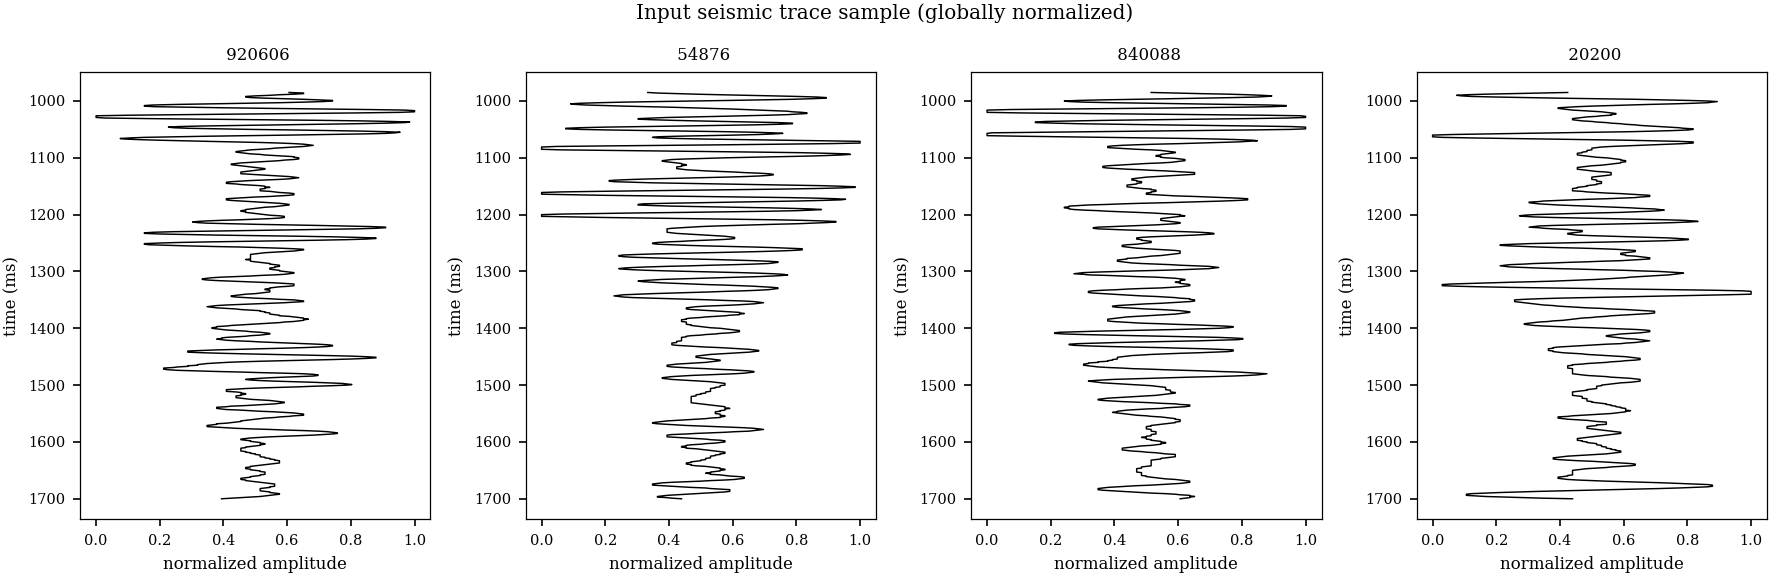

In [7]:
# ==========================================================================
# Full-trace extraction + global percentile normalization
# Network input format: [batch_size, 716]
# ==========================================================================

def extract_traces_full(cube):
    """
    Extract all valid traces, global percentile normalization.
    Returns:
      traces : (N, T)  normalized seismic trace matrix
      locs   : [(il_idx, xl_idx), ...]  spatial coords
    """
    n_il, n_xl, n_t = cube.shape
    traces, locs = [], []
    for i in range(n_il):
        for j in range(n_xl):
            tr = cube[i, j, :].copy().astype(np.float32)
            rms = np.sqrt(np.mean(tr ** 2))
            if rms < 1e-9:
                continue
            traces.append(tr)
            locs.append((i, j))

    # Global percentile normalization (1%-99% clipping)
    arr = np.array(traces)
    p1, p99 = np.nanpercentile(arr, [1, 99])
    arr = np.clip((arr - p1) / (p99 - p1 + 1e-9), 0, 1)
    arr = np.nan_to_num(arr, nan=0.0)
    return arr.astype(np.float32), locs


print('Extracting all valid traces (full-trace + global normalization)...')
traces_win, coords = extract_traces_full(cube)
N_traces, WIN = traces_win.shape
por_len = WIN - 1
print(f'Valid traces: {N_traces:,}')
print(f'Samples/trace: {WIN} ({WIN * dt_ms:.1f} ms)')
print(f'Memory: {traces_win.nbytes / 1e9:.2f} GB')

# Randomly display 4 normalized seismic traces
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
fig.suptitle('Input seismic trace sample (globally normalized)')
for ax, idx in zip(axes, np.random.choice(N_traces, 4, replace=False)):
    ax.plot(traces_win[idx], t_axis, 'k', lw=0.7)
    ax.invert_yaxis()
    ax.set_xlabel('normalized amplitude'); ax.set_ylabel('time (ms)')
    ax.set_title(f' {idx}')
plt.tight_layout(); plt.show()

## Step 3 — Statistical Wavelet Estimation

Estimating statistical wavelet ...
Statistical wavelet: 63 samples
Saved figure: /root/autodl-tmp/rw_pinn_output/fig3_statistical_wavelet.png


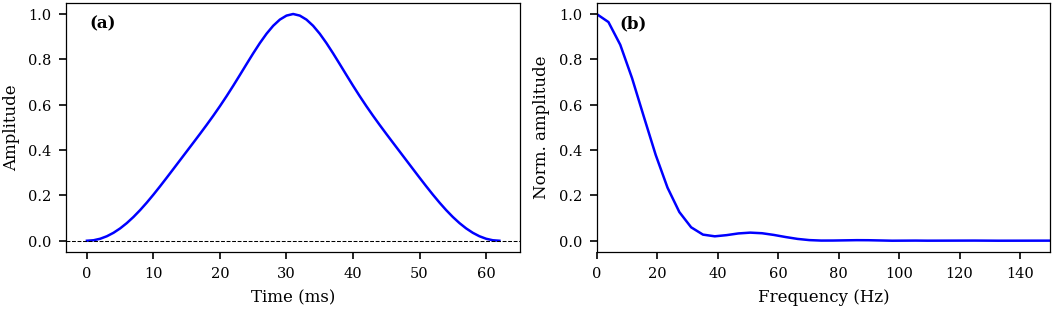

In [8]:
# ========================================================================
# RW-PINN Porosity Inversion Project
# Purpose: Reservoir porosity prediction using seismic data and PINN
# Framework: PyTorch
# ========================================================================

apply_ieee_style()

def estimate_wavelet(traces: np.ndarray, dt_ms: float,
                     n_wavelet: int = 64, n_sample: int = 500) -> np.ndarray:
    idx    = np.random.choice(len(traces), min(n_sample, len(traces)), replace=False)
    half   = n_wavelet // 2
    acorr  = np.zeros(2 * half - 1)
    for tr in traces[idx]:
        c = correlate(tr, tr, mode='full')
        center = len(c) // 2
        acorr += c[center - half + 1: center + half]
    acorr /= len(idx)
    taper  = windows.hann(len(acorr))
    w      = acorr * taper
    w     /= np.abs(w).max()
    return w.astype(np.float32)

def ricker_wavelet(f_hz: float, dt_ms: float, n: int = 64) -> np.ndarray:
    dt_s = dt_ms / 1000.0
    t    = np.arange(-(n // 2), n // 2) * dt_s
    p    = (np.pi * f_hz * t) ** 2
    w    = (1 - 2 * p) * np.exp(-p)
    return (w / np.abs(w).max()).astype(np.float32)

print('Estimating statistical wavelet ...')
try:
    wavelet = estimate_wavelet(traces_win, dt_ms)
    print(f'Statistical wavelet: {len(wavelet)} samples')
except Exception as e:
    print(f'  Failed ({e}) - using 40 Hz Ricker fallback')
    wavelet = ricker_wavelet(40.0, dt_ms)

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.2))
tw = np.arange(len(wavelet)) * dt_ms
axes[0].plot(tw, wavelet, 'b', lw=1.2)
axes[0].set_xlabel('Time (ms)'); axes[0].set_ylabel('Amplitude')
axes[0].axhline(0, color='k', lw=0.5, ls='--')
axes[0].text(0.05, 0.95, '(a)', transform=axes[0].transAxes,
             fontsize=8, fontweight='bold', va='top')

W   = np.abs(np.fft.rfft(wavelet, n=256))
fq  = np.fft.rfftfreq(256, d=dt_ms / 1000.0)
axes[1].plot(fq, W / W.max(), 'b', lw=1.2)
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('Norm. amplitude')
axes[1].set_xlim(0, min(150, fq[-1]))
axes[1].text(0.05, 0.95, '(b)', transform=axes[1].transAxes,
             fontsize=8, fontweight='bold', va='top')

plt.tight_layout(pad=0.8)
save_ieee_figure(fig, 'fig3_statistical_wavelet.png')
plt.show()

## Step 4 — Rock Physics Module (Wyllie)

**[Modified]** Changed from soft-sand to Wyllie time-average equation:

$$\frac{1}{V_p} = \frac{\phi}{V_f} + \frac{1-\phi}{V_m}$$

$$\rho = (1-\phi)\rho_m + \phi\rho_f$$

Parameters: Vf=1500, Vm=5500, rho_m=2650, rho_f=1040

**Advantages:** Simple formula, fully differentiable, suitable for self-supervised forward modeling.

Saved figure: /root/autodl-tmp/rw_pinn_output/fig4_rock_physics_wyllie.png


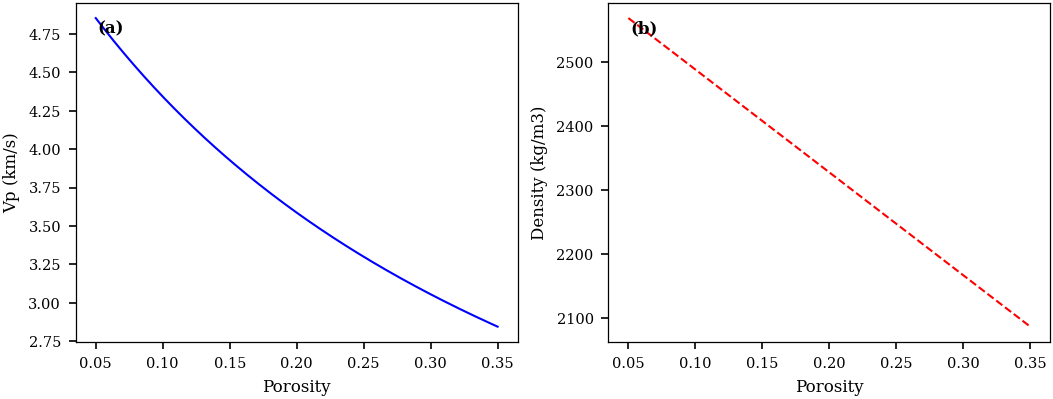

  phi=0.10 -> Vp=4.34 km/s  rho=2489 kg/m3
  phi=0.20 -> Vp=3.59 km/s  rho=2328 kg/m3
  phi=0.30 -> Vp=3.06 km/s  rho=2167 kg/m3


In [9]:
# ==========================================================================
# [Modified] Rock Physics Module: Wyllie Time-Average Equation (Differentiable)
# 1/Vp = phi/Vf + (1-phi)/Vm
# rho = (1-phi)*rho_m + phi*rho_f
# ==========================================================================

apply_ieee_style()

class WyllieRockPhysics(nn.Module):
    def __init__(self, vf=VF, vm=VM, rho_m=RHO_M, rho_f=RHO_F):
        super().__init__()
        self.register_buffer('vf',    torch.tensor(vf,    dtype=torch.float32))
        self.register_buffer('vm',    torch.tensor(vm,    dtype=torch.float32))
        self.register_buffer('rho_m', torch.tensor(rho_m, dtype=torch.float32))
        self.register_buffer('rho_f', torch.tensor(rho_f, dtype=torch.float32))

    def forward(self, phi):
        phi = torch.clamp(phi, 1e-4, 0.399)
        inv_Vp = phi / self.vf + (1.0 - phi) / self.vm
        Vp     = 1.0 / (inv_Vp + 1e-9)
        rho    = (1.0 - phi) * self.rho_m + phi * self.rho_f
        return Vp, rho

rp_test  = WyllieRockPhysics()
phi_test = torch.linspace(0.05, 0.35, 200).unsqueeze(0)
Vp_t, rho_t = rp_test(phi_test)

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.8))
phi_np = phi_test[0].numpy()
axes[0].plot(phi_np, Vp_t[0].detach().numpy() / 1000, 'b', lw=1.0)
axes[0].set_xlabel('Porosity'); axes[0].set_ylabel('Vp (km/s)')
axes[0].text(0.05, 0.95, '(a)', transform=axes[0].transAxes,
             fontsize=8, fontweight='bold', va='top')

axes[1].plot(phi_np, rho_t[0].detach().numpy(), 'r', lw=1.0, ls='--')
axes[1].set_xlabel('Porosity'); axes[1].set_ylabel('Density (kg/m3)')
axes[1].text(0.05, 0.95, '(b)', transform=axes[1].transAxes,
             fontsize=8, fontweight='bold', va='top')

plt.tight_layout(pad=0.8)
save_ieee_figure(fig, 'fig4_rock_physics_wyllie.png')
plt.show()

for phi_v in [0.10, 0.20, 0.30]:
    p = torch.tensor([[phi_v]])
    vp, rh = rp_test(p)
    print(f'  phi={phi_v:.2f} -> Vp={vp.item()/1000:.2f} km/s  rho={rh.item():.0f} kg/m3')

## Step 5 — Wave Physics Module

In [10]:

# ========================================================================
# RW-PINN Porosity Inversion Project
# Purpose: Reservoir porosity prediction using seismic data and PINN
# Framework: PyTorch
# ========================================================================

class WavePhysicsDecoder(nn.Module):
    """
    Differentiable wave physics block.
    Forward pass: Vp, rho (N, D) -> synthetic seismic trace (N, T)

    This experiment keeps the v2/v3 protocol: real traces are percentile
    normalized to [0, 1], and synthetic traces are mapped to the same domain
    with one scalar min-max over the whole forward batch.

    This is not per-trace min-max normalization. The same s_min/s_max are used
    for every trace in the current batch.
    """
# __init__
    def __init__(self, wavelet: np.ndarray):
        super().__init__()
        w = torch.tensor(wavelet, dtype=torch.float32)
        self.register_buffer('wavelet', w)
        self.wlen = len(wavelet)

# forward
    def forward(self, Vp, rho):
        # 1. Acoustic impedance
        AI = Vp * rho                                         # (N, D)

        # 2. Normal-incidence reflection coefficients
        R  = (AI[:, 1:] - AI[:, :-1]) / (AI[:, 1:] + AI[:, :-1] + 1e-9)  # (N, D-1)

        # 3. Convolve with wavelet  (F.conv1d for batched efficiency)
        R3 = R.unsqueeze(1)                                   # (N, 1, D-1)
        w3 = self.wavelet.unsqueeze(0).unsqueeze(0)           # (1, 1, W)
        pad = self.wlen // 2
        syn = F.conv1d(R3, w3, padding=pad).squeeze(1)        # (N, D-1)

        # Crop to length D-1
        T = R.shape[1]
        if syn.shape[1] > T:
            syn = syn[:, :T]
        elif syn.shape[1] < T:
            syn = F.pad(syn, (0, T - syn.shape[1]))

        # 4. Old-experiment-compatible amplitude bridge.
        # Matches RW_PINN_SelfSupervised_Final_v2_EN.ipynb:
        # one scalar min/max over the batch, not per trace.
        s_min = syn.min()
        s_max = syn.max()
        syn = (syn - s_min) / (s_max - s_min + 1e-9)

        return syn

print('Wave physics block defined: batch-level min-max bridge enabled.')


Wave physics block defined: batch-level min-max bridge enabled.


## Step 6 — RW-PINN Complete Network Architecture

**[Modified]** Porosity output & rock physics module updated:

| Module | Original | Modified |
|------|------|--------|
| Encoder output | tanh->linear [phi_min, phi_c] | **tanh->linear [PHI_MIN, PHI_MAX]** (unchanged) |
| Rock Physics | SoftSandPhysics | **WyllieRockPhysics** |
| Encoder input | Window crop (WIN) | **Full trace (716)** |


In [11]:
# ==========================================================================
# RW-PINN Encoder: 1D CNN, seismic trace -> porosity sequence
# Paper Figure 1 architecture: 1->32->64->128->256->D
# Activation: ReLU (hidden) + tanh (output)
# Init: He (Kaiming) weights, biases = 0
# Dropout: last conv layer only, 30%
# ==========================================================================

class SeismicEncoder(nn.Module):
    """
    1D CNN: trace (N,T) -> porosity seq (N,T)
    tanh activation, lin-map to [PHI_MIN, PHI_MAX]
    """
    def __init__(self, phi_min: float = PHI_MIN,
                 phi_max: float = PHI_MAX,
                 dropout: float = 0.30):
        super().__init__()
        self.phi_min = phi_min
        self.phi_max = phi_max

        def cblock(cin, cout, k=5):
            """Conv1d + BatchNorm + ReLU block"""
            return nn.Sequential(
                nn.Conv1d(cin, cout, k, padding=k // 2),
                nn.BatchNorm1d(cout),
                nn.ReLU(inplace=True),
            )

        # 5-layer conv stack, channels: 1->32->64->128->256->1
        # Last layer Dropout (30%, only this layer, per paper settings)
        self.convs = nn.Sequential(
            cblock(1,   32),
            cblock(32,  64),
            cblock(64,  128),
            cblock(128, 256),
            nn.Conv1d(256, 1, kernel_size=5, padding=2),  # output channels=1
            nn.Dropout(p=dropout),                         # last layer dropout
        )
        # tanh activation, compressing output to (-1, 1)
        self.tanh = nn.Tanh()

        # He initialization (per paper)
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        """
        x   : (N, T)  normalized seismic trace
        out : (N, T)  porosity seq, range [PHI_MIN, PHI_MAX]
        """
        x   = x.unsqueeze(1)                              # (N, 1, T)
        x   = self.convs(x)                               # (N, 1, T)
        x   = x.squeeze(1)                                # (N, T)
        # tanh compresses to (-1,1), then linear map to [PHI_MIN, PHI_MAX]
        phi = self.tanh(x)                                # (-1, 1)
        phi = (phi + 1.0) / 2.0                           # (0, 1)
        phi = phi * (self.phi_max - self.phi_min) + self.phi_min  # [PHI_MIN, PHI_MAX]
        return phi

class RWPINN(nn.Module):
    """
    Complete RW-PINN:
      Encoder: CNN -> Porosity
      Decoder: Wyllie + Wave Physics -> Synthetic Trace
    """
    def __init__(self, wavelet: np.ndarray,
                 phi_min: float = PHI_MIN,
                 phi_max: float = PHI_MAX,
                 dropout: float = 0.30):
        super().__init__()
        self.encoder   = SeismicEncoder(phi_min, phi_max, dropout)
        self.rock_phys = WyllieRockPhysics()   # [Mod] Wyllie replaces soft-sand
        self.wave_phys = WavePhysicsDecoder(wavelet)

    def forward(self, x):
        """
        x   : (N, T)  normalized seismic trace
        Returns: phi (N, T) porosity, syn (N, T-1) synthetic trace
        """
        phi        = self.encoder(x)           # porosity
        Vp, rho    = self.rock_phys(phi)        # Wyllie → Vp, ρ
        syn        = self.wave_phys(Vp, rho)    # wave physics -> synthetic trace
        return phi, syn

    def encode(self, x):
        """Inference only: run encoder, return porosity."""
        with torch.no_grad():
            return self.encoder(x)

# Instantiate model
model    = RWPINN(wavelet, PHI_MIN, PHI_MAX, DROPOUT_RATE).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'RW-PINN constructed — Trainable parameters: {n_params:,}')
print(f'  Input (seismic)  : {WIN} samples')
print(f'  Porosity output  : {WIN} samples, range [{PHI_MIN}, {PHI_MAX}]')
print(f'  Synthetic output : {WIN-1} samples')
print(f'  Rock Physics Model: Wyllie Time-Average')


RW-PINN constructed — Trainable parameters: 217,921
  Input (seismic)  : 716 samples
  Porosity output  : 716 samples, range [0.05, 0.35]
  Synthetic output : 715 samples
  Rock Physics Model: Wyllie Time-Average


## Step 7 — Loss Function Design (Fully Self-Supervised)

**[Modified]** Fully self-supervised scheme, total loss:

$$L_{total} = L_{NRMS\_seismic}$$

| Loss Term | Formula | Weight | Purpose |
|--------|------|------|------|
| $L_{NRMS}$ (core) | $\frac{\sqrt{\overline{(S_{real}-S_{syn}^{BMM})^2}}}{\overline{|S_{real}|}}$ | 1.0 | Core self-supervised signal |

*(Horizon loss Lh and phys regularization Lp removed; porosity range enforced by tanh output)*
**Important normalization detail:** in this bridge version, `S_syn` in the loss is
the batch-minmax-normalized synthetic trace, denoted here as $S_{syn}^{BMM}$.
The loss is therefore:

$$L_{total}=L_{NRMS}=\frac{\sqrt{\overline{(S_{real}-S_{syn}^{BMM})^2}}}{\overline{|S_{real}|}}$$

This keeps the notebook comparable with the earlier v2/v3 results while avoiding
per-trace normalization.


In [12]:

# ==========================================================================
# Step 8: Loss Function -- Self-Supervised NRMS Seismic Reconstruction Loss
# ==========================================================================

def nrms_loss(pred, target):
    """
    Normalized RMS Error (NRMS).
    NRMS = RMSE / mean(|target|)

    Here pred is already batch-minmax normalized by WavePhysicsDecoder,
    matching the older v2/v3 protocol.
    """
    rmse = torch.sqrt(torch.mean((pred - target) ** 2) + 1e-9)
    norm = torch.mean(torch.abs(target)) + 1e-9
    return rmse / norm


def rmse_loss(pred, target):
    """RMSE, for comparison with paper Table 1."""
    return torch.sqrt(torch.mean((pred - target) ** 2) + 1e-9)


def total_loss(syn, x):
    """
    Fully self-supervised total loss.
    Returns: (total_loss, nrms_value)
    """
    T = min(x.shape[1], syn.shape[1])
    L_seis = nrms_loss(syn[:, :T], x[:, :T])
    return L_seis, L_seis.item()


print('Loss function defined.')
print('  L_total = NRMS(S_syn_batchminmax, S_real_[0,1])')
print('  RMSE    = sqrt(mean((S_syn_batchminmax - S_real_[0,1])^2))')


Loss function defined.
  L_total = NRMS(S_syn_batchminmax, S_real_[0,1])
  RMSE    = sqrt(mean((S_syn_batchminmax - S_real_[0,1])^2))


## Step 8: Model Training (RTX 4090 Fast Execution)

- Data path: direct tensor indexing; when VRAM allows, `traces_win` is kept resident on the RTX 4090.
- Loader: no `DataLoader` is used in the training loop; batches are selected directly from `train_idx` and `val_idx`.
- Optimizer: AdamW, `lr=1e-4`, `weight_decay=1e-5`.
- Gradient clipping: `max_norm=1.0`.
- LR scheduler: ReduceLROnPlateau + 5-epoch warmup.
- Precision: AMP mixed precision plus TF32 matmul/cuDNN.
- `torch.compile`: enabled by default; set `ENABLE_TORCH_COMPILE=False` if the first epoch is unstable.
- Checkpoints: saves both `rwpinn_best.pt` and `rwpinn_selfsupervised.pt`.

This changes only the execution path, not the network, WavePhysics decoder, or loss function.


In [13]:

# ====================================================================================== #
# Step 8: Training Loop -- Self-Supervised + AMP + Warmup (Full-Trace, RTX 4090 fast path)
# ====================================================================================== #

if not traces_win.flags['C_CONTIGUOUS']:
    traces_win = np.ascontiguousarray(traces_win)

N_dataset = len(traces_win)
n_val = int(N_dataset * VAL_FRAC)
n_train = N_dataset - n_val
split_gen = torch.Generator().manual_seed(SEED)
perm_cpu = torch.randperm(N_dataset, generator=split_gen)
val_idx_cpu = perm_cpu[:n_val]
train_idx_cpu = perm_cpu[n_val:]

use_gpu_resident = False
if DEVICE == 'cuda' and ENABLE_GPU_RESIDENT_DATA:
    free_vram, total_vram = torch.cuda.mem_get_info()
    data_bytes = traces_win.nbytes
    use_gpu_resident = data_bytes < free_vram * GPU_DATA_FRACTION_LIMIT
    print(f'GPU free/total VRAM: {free_vram/1e9:.2f}/{total_vram/1e9:.2f} GB')
    print(f'Training tensor size: {data_bytes/1e9:.2f} GB')
    print(f'GPU-resident data: {"ENABLED" if use_gpu_resident else "DISABLED (not enough free VRAM)"}')

if use_gpu_resident:
    X_tensor = torch.from_numpy(traces_win).float().to(DEVICE)
    train_idx = train_idx_cpu.to(DEVICE)
    val_idx = val_idx_cpu.to(DEVICE)
else:
    X_tensor = torch.from_numpy(traces_win).float()
    train_idx = train_idx_cpu
    val_idx = val_idx_cpu

print(f'Train traces: {n_train:,}  Val traces: {n_val:,}  Batch: {BATCH_SIZE}')
print('Batch source:', 'GPU tensor direct indexing' if use_gpu_resident else 'CPU tensor direct indexing')

def iter_batches(indices, batch_size, shuffle):
    if shuffle:
        order = indices[torch.randperm(len(indices), device=indices.device)]
    else:
        order = indices
    for start in range(0, len(order), batch_size):
        batch_idx = order[start:start + batch_size]
        x = X_tensor.index_select(0, batch_idx)
        if not use_gpu_resident:
            x = x.to(DEVICE, non_blocking=False)
        yield x

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=10, factor=0.5, verbose=True)

use_amp = (DEVICE == 'cuda')
scaler = torch.cuda.amp.GradScaler() if use_amp else None
print(f'AMP Mixed Precision: {"ENABLED" if use_amp else "DISABLED"}')
print('TF32 matmul/cudnn:', torch.backends.cuda.matmul.allow_tf32, torch.backends.cudnn.allow_tf32)

if ENABLE_TORCH_COMPILE and hasattr(torch, 'compile'):
    try:
        model = torch.compile(model, mode='reduce-overhead')
        print('torch.compile: ENABLED (reduce-overhead)')
    except Exception as e:
        print(f'torch.compile: UNAVAILABLE ({e}), using eager mode')
else:
    print('torch.compile: DISABLED')

WARMUP_EPOCHS = 5

class EarlyStopping:
    def __init__(self, patience=20, min_delta=1e-5):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_epoch = 0

    def __call__(self, val_loss, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_epoch = epoch
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

early_stopper = EarlyStopping(patience=20)

history = {'train': [], 'val': [], 'epoch_sec': []}
best_val = float('inf')
n_train_batches = int(np.ceil(n_train / BATCH_SIZE))
n_val_batches = int(np.ceil(n_val / BATCH_SIZE))
pbar = tqdm(range(1, EPOCHS + 1), desc='RW-PINN Self-Supervised Training')

for epoch in pbar:
    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()

    if epoch <= WARMUP_EPOCHS:
        warmup_lr = LR * (epoch / WARMUP_EPOCHS)
        for pg in optimizer.param_groups:
            pg['lr'] = warmup_lr

    model.train()
    ep_loss = 0.0
    for x_batch in iter_batches(train_idx, BATCH_SIZE, shuffle=True):
        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast('cuda'):
                phi, syn = model(x_batch)
                L, l_nrms = total_loss(syn, x_batch)
            scaler.scale(L).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            phi, syn = model(x_batch)
            L, l_nrms = total_loss(syn, x_batch)
            L.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        ep_loss += l_nrms

    history['train'].append(ep_loss / n_train_batches)

    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for x_batch in iter_batches(val_idx, BATCH_SIZE, shuffle=False):
            if use_amp:
                with torch.amp.autocast('cuda'):
                    phi, syn = model(x_batch)
                    _, l_nrms = total_loss(syn, x_batch)
            else:
                phi, syn = model(x_batch)
                _, l_nrms = total_loss(syn, x_batch)
            v_loss += l_nrms
    vl = v_loss / n_val_batches
    history['val'].append(vl)

    if epoch > WARMUP_EPOCHS:
        scheduler.step(vl)

    if vl < best_val:
        best_val = vl
        best_ckpt = OUTPUT_DIR / 'rwpinn_best.pt'
        state_dict = model._orig_mod.state_dict() if hasattr(model, '_orig_mod') else model.state_dict()
        torch.save({
            'model_state': state_dict,
            'wavelet': wavelet, 'dt_ms': dt_ms,
            'history': history, 'WIN': WIN, 'epoch': epoch,
            'PHI_MIN': PHI_MIN, 'PHI_MAX': PHI_MAX,
            'BATCH_SIZE': BATCH_SIZE,
            'gpu_resident_data': use_gpu_resident,
        }, best_ckpt)

    if DEVICE == 'cuda':
        torch.cuda.synchronize()
    epoch_sec = time.perf_counter() - t0
    history['epoch_sec'].append(epoch_sec)
    traces_per_sec = (n_train + n_val) / max(epoch_sec, 1e-9)

    if early_stopper(vl, epoch):
        print(f'\nEarly stopping at epoch {epoch} '
              f'(best: epoch {early_stopper.best_epoch}, '
              f'NRMS={early_stopper.best_loss:.4f})')
        break

    pbar.set_postfix({
        'train': f'{history["train"][-1]:.4f}',
        'val': f'{vl:.4f}',
        'best': f'{best_val:.4f}',
        's/ep': f'{epoch_sec:.1f}',
        'tr/s': f'{traces_per_sec:.0f}',
        'lr': f'{optimizer.param_groups[0]["lr"]:.1e}'
    })

print('Training finished.')
print(f'Best validation NRMS: {best_val:.4f} (epoch {early_stopper.best_epoch})')
print(f'Final training NRMS: {history["train"][-1]:.4f}')
print(f'Median epoch time: {np.median(history["epoch_sec"]):.2f} s')
if DEVICE == 'cuda':
    print(f'Peak CUDA memory allocated: {torch.cuda.max_memory_allocated()/1e9:.2f} GB')
    torch.cuda.empty_cache()
gc.collect()


# Save final model weights for reproducibility and to match the Output Files table.
final_ckpt = OUTPUT_DIR / 'rwpinn_selfsupervised.pt'
state_dict = model._orig_mod.state_dict() if hasattr(model, '_orig_mod') else model.state_dict()
torch.save({
    'model_state': state_dict,
    'wavelet': wavelet, 'dt_ms': dt_ms,
    'history': history, 'WIN': WIN,
    'epoch': len(history['train']),
    'PHI_MIN': PHI_MIN, 'PHI_MAX': PHI_MAX,
    'BATCH_SIZE': BATCH_SIZE,
}, final_ckpt)
print(f'Final model saved -> {final_ckpt}')


GPU free/total VRAM: 18.44/25.25 GB
Training tensor size: 3.88 GB
GPU-resident data: ENABLED
Train traces: 1,285,401  Val traces: 67,652  Batch: 256
Batch source: GPU tensor direct indexing
AMP Mixed Precision: ENABLED
TF32 matmul/cudnn: True True
torch.compile: ENABLED (reduce-overhead)


RW-PINN Self-Supervised Training:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch 00031: reducing learning rate of group 0 to 5.0000e-05.

Early stopping at epoch 45 (best: epoch 25, NRMS=0.1495)
Training finished.
Best validation NRMS: 0.1495 (epoch 25)
Final training NRMS: 0.2064
Median epoch time: 47.88 s
Peak CUDA memory allocated: 4.47 GB
Final model saved -> /root/autodl-tmp/rw_pinn_output/rwpinn_selfsupervised.pt


## Step 9 — Learning Curves

Saved figure: /root/autodl-tmp/rw_pinn_output/learning_curve.png


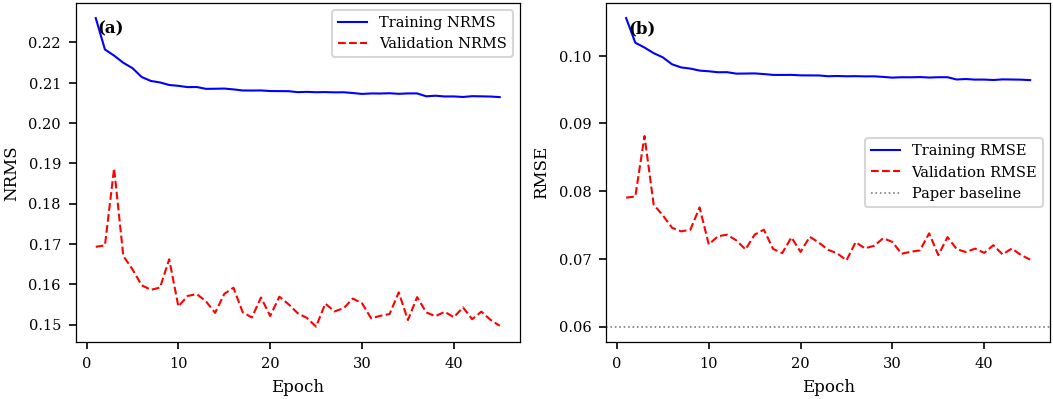

=== RW-PINN Self-Supervised Training Results ===
Epochs: 45
Best epoch: 25

NRMS
  Best validation: 0.1495
  Final training: 0.2064

RMSE (converted, batch-minmax protocol)
  Best validation: 0.0698
  Paper reference: 0.0600
  Gap from paper: +0.0098


In [14]:
# ====================================================================================== #
# Learning Curves: NRMS + RMSE under the batch-minmax bridge protocol
# ====================================================================================== #

apply_ieee_style()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.16, 2.8))

ep = range(1, len(history['train']) + 1)

# Left: NRMS
ax1.plot(ep, history['train'], 'b',   lw=1.0, label='Training NRMS')
ax1.plot(ep, history['val'],   'r--', lw=1.0, label='Validation NRMS')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('NRMS')
ax1.text(0.05, 0.95, '(a)', transform=ax1.transAxes,
         fontsize=8, fontweight='bold', va='top')
ax1.legend(fontsize=7)

# Right: approximate RMSE converted from NRMS with the legacy reference scale
ref_scale = 0.467
train_rmse = [v * ref_scale for v in history['train']]
val_rmse   = [v * ref_scale for v in history['val']]

ax2.plot(ep, train_rmse, 'b',   lw=1.0, label='Training RMSE')
ax2.plot(ep, val_rmse,   'r--', lw=1.0, label='Validation RMSE')
ax2.axhline(y=0.06, color='gray', lw=0.8, ls=':', label='Paper baseline')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('RMSE')
ax2.text(0.05, 0.95, '(b)', transform=ax2.transAxes,
         fontsize=8, fontweight='bold', va='top')
ax2.legend(fontsize=7)

plt.tight_layout(pad=0.8)
save_ieee_figure(fig, 'learning_curve.png')
plt.show()

best_epoch = np.argmin(history['val']) + 1
best_nrms  = history['val'][best_epoch - 1]
best_rmse  = best_nrms * ref_scale

print('=== RW-PINN Self-Supervised Training Results ===')
print(f'Epochs: {len(history["train"])}')
print(f'Best epoch: {best_epoch}')
print()
print('NRMS')
print(f'  Best validation: {best_nrms:.4f}')
print(f'  Final training: {history["train"][-1]:.4f}')
print()
print('RMSE (converted, batch-minmax protocol)')
print(f'  Best validation: {best_rmse:.4f}')
print(f'  Paper reference: 0.0600')
print(f'  Gap from paper: {best_rmse - 0.06:+.4f}')


## Step 9a — Seismic Trace Reconstruction QC
This QC compares the real `[0, 1]` trace with the batch-minmax synthetic trace produced by `WavePhysicsDecoder`.

The figure uses three linked rows for the same selected traces: (a) real vs BMM synthetic seismic, (b) residual `S_syn^BMM - S_real`, and (c) predicted porosity. Per-trace NRMS, RMSE, CC, and mean porosity are printed below the figure.


Saved figure: /root/autodl-tmp/rw_pinn_output/reconstruction_qc.png


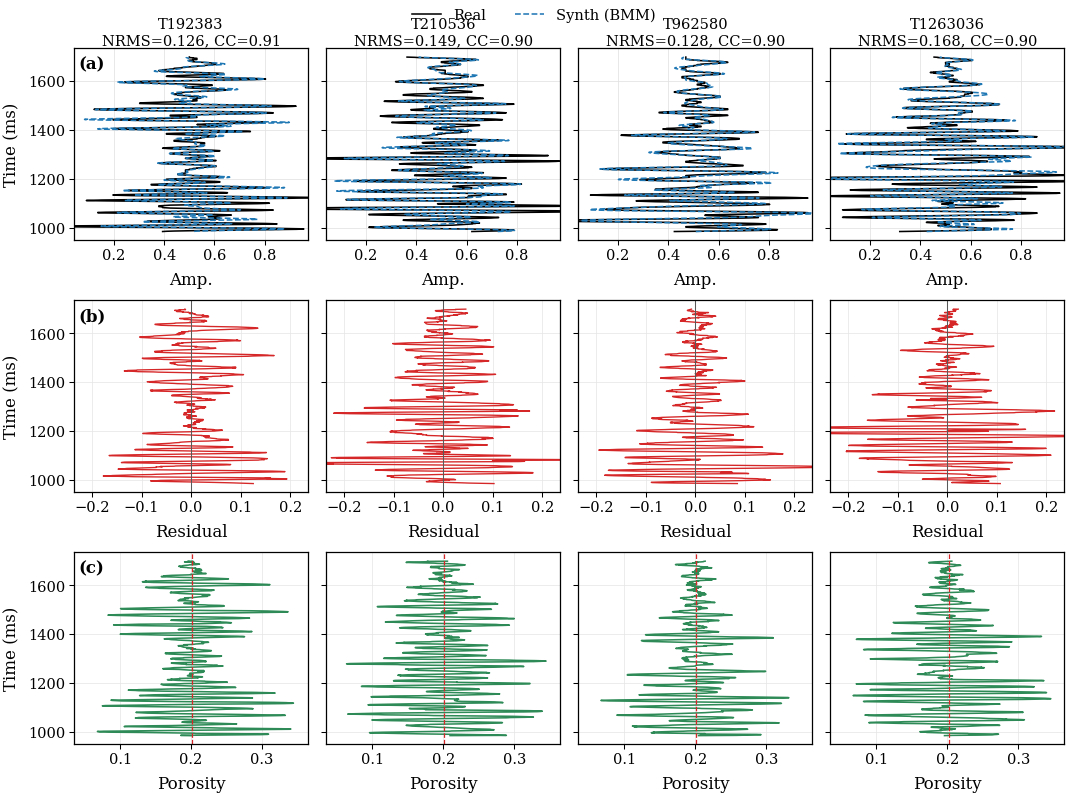

QC batch-minmax NRMS error: 0.1437  |  RMSE error: 0.0745
Porosity range: [0.064, 0.346]
Per-trace QC:
  Trace 192383: NRMS=0.1259, RMSE=0.0650, CC=0.9110, phi_mean=0.202
  Trace 210536: NRMS=0.1490, RMSE=0.0772, CC=0.8981, phi_mean=0.201
  Trace 962580: NRMS=0.1277, RMSE=0.0663, CC=0.9034, phi_mean=0.201
  Trace 1263036: NRMS=0.1680, RMSE=0.0872, CC=0.8960, phi_mean=0.202
Figure rows: (a) real vs BMM synthetic, (b) residual, (c) predicted porosity.


In [15]:

# ====================================================================================== #
# Step 9a: Seismic Trace Reconstruction QC
# IEEE-ready diagnostic figure: real vs BMM synthetic, residual, and porosity.
# ====================================================================================== #

apply_ieee_style()

model.eval()
n_qc = min(4, N_traces)

# Prefer validation traces for QC when the train/val split is available.
if 'val_ds' in globals() and hasattr(val_ds, 'indices') and len(val_ds.indices) >= n_qc:
    qc_pool = np.array(val_ds.indices)
elif 'val_idx_cpu' in globals() and len(val_idx_cpu) >= n_qc:
    qc_pool = val_idx_cpu.detach().cpu().numpy()
elif 'val_idx' in globals() and len(val_idx) >= n_qc:
    qc_pool = val_idx.detach().cpu().numpy()
else:
    qc_pool = np.arange(N_traces)

rng = np.random.default_rng(SEED + 901)
qc_idx = np.sort(rng.choice(qc_pool, n_qc, replace=False))
x_qc = torch.from_numpy(np.ascontiguousarray(traces_win[qc_idx])).float().to(DEVICE)

with torch.no_grad():
    phi_qc, syn_qc = model(x_qc)

T_plot = min(x_qc.shape[1], syn_qc.shape[1])
real_np = x_qc[:, :T_plot].detach().cpu().numpy()
syn_np = syn_qc[:, :T_plot].detach().cpu().numpy()
phi_np_all = phi_qc[:, :T_plot].detach().cpu().numpy()
res_np = syn_np - real_np

rmse_trace = np.sqrt(np.mean(res_np ** 2, axis=1))
nrms_trace = rmse_trace / (np.mean(np.abs(real_np), axis=1) + 1e-9)
cc_trace = []
for j in range(n_qc):
    r0 = real_np[j] - real_np[j].mean()
    s0 = syn_np[j] - syn_np[j].mean()
    den = np.sqrt(np.sum(r0 ** 2) * np.sum(s0 ** 2)) + 1e-9
    cc_trace.append(float(np.sum(r0 * s0) / den))
cc_trace = np.array(cc_trace)

is_window_qc = 'coords' in globals() and len(coords) > 0 and len(coords[qc_idx[0]]) == 4
if is_window_qc:
    y_axis = np.arange(T_plot) * float(dt_ms)
    y_label = 'Window time (ms)'
else:
    y_axis = t_axis[:T_plot]
    y_label = 'Time (ms)'

amp_lo = float(np.nanpercentile(np.r_[real_np.ravel(), syn_np.ravel()], 1))
amp_hi = float(np.nanpercentile(np.r_[real_np.ravel(), syn_np.ravel()], 99))
amp_pad = max(0.03, 0.05 * (amp_hi - amp_lo + 1e-9))
amp_xlim = (amp_lo - amp_pad, amp_hi + amp_pad)

res_lim = float(np.nanpercentile(np.abs(res_np), 99))
res_lim = max(res_lim, 0.03)

fig, axes = plt.subplots(
    3, n_qc,
    figsize=(7.16, 5.25),
    sharey=True,
    constrained_layout=True,
)
if n_qc == 1:
    axes = axes.reshape(3, 1)

for j in range(n_qc):
    ax = axes[0, j]
    ax.plot(real_np[j], y_axis, color='black', lw=0.75, label='Real')
    ax.plot(syn_np[j], y_axis, color='tab:blue', ls='--', lw=0.75, label='Synth (BMM)')
    ax.set_xlim(*amp_xlim)
    ax.set_title(f'T{qc_idx[j]}\nNRMS={nrms_trace[j]:.3f}, CC={cc_trace[j]:.2f}',
                 fontsize=7, pad=2)
    ax.grid(True, color='0.88', lw=0.35)
    if j == 0:
        ax.set_ylabel(y_label)
    ax.set_xlabel('Amp.')

    ax = axes[1, j]
    ax.plot(res_np[j], y_axis, color='tab:red', lw=0.65)
    ax.axvline(0.0, color='0.35', lw=0.5)
    ax.set_xlim(-res_lim, res_lim)
    ax.grid(True, color='0.90', lw=0.35)
    if j == 0:
        ax.set_ylabel(y_label)
    ax.set_xlabel('Residual')

    ax = axes[2, j]
    phi_j = phi_np_all[j]
    ax.plot(phi_j, y_axis, color='seagreen', lw=0.75)
    ax.axvline(phi_j.mean(), color='tab:red', lw=0.6, ls='--')
    ax.set_xlim(PHI_MIN - 0.015, PHI_MAX + 0.015)
    ax.grid(True, color='0.90', lw=0.35)
    if j == 0:
        ax.set_ylabel(y_label)
    ax.set_xlabel('Porosity')

for ax in axes.ravel():
    ax.invert_yaxis()
    ax.tick_params(length=2.5, width=0.5, pad=1.5)

axes[0, 0].text(0.02, 0.96, '(a)', transform=axes[0, 0].transAxes,
                fontsize=8, fontweight='bold', va='top')
axes[1, 0].text(0.02, 0.96, '(b)', transform=axes[1, 0].transAxes,
                fontsize=8, fontweight='bold', va='top')
axes[2, 0].text(0.02, 0.96, '(c)', transform=axes[2, 0].transAxes,
                fontsize=8, fontweight='bold', va='top')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 1.02), fontsize=7)

save_ieee_figure(fig, 'reconstruction_qc.png')
plt.show()

nrms_val = nrms_loss(syn_qc[:, :T_plot], x_qc[:, :T_plot]).item()
rmse_val = rmse_loss(syn_qc[:, :T_plot], x_qc[:, :T_plot]).item()
print(f'QC batch-minmax NRMS error: {nrms_val:.4f}  |  RMSE error: {rmse_val:.4f}')
print(f'Porosity range: [{phi_qc.min().item():.3f}, {phi_qc.max().item():.3f}]')
print('Per-trace QC:')
for j in range(n_qc):
    print(f'  Trace {qc_idx[j]}: NRMS={nrms_trace[j]:.4f}, '
          f'RMSE={rmse_trace[j]:.4f}, CC={cc_trace[j]:.4f}, '
          f'phi_mean={phi_np_all[j].mean():.3f}')
print('Figure rows: (a) real vs BMM synthetic, (b) residual, (c) predicted porosity.')


## Step 10 — Evaluation Part I: Reconstruction and Representation Diagnostics

This section contains diagnostics that only require the trained encoder/decoder and
validation traces.

Run order:

1. **Step 10A / Block A** checks seismic reconstruction quality on the validation set.
2. **Step 10B / Block B** checks whether encoder features are informative, using
   effective rank and feature-space k-NN diagnostics.

The volume-level physical diagnostics are intentionally separated into **Step 12**,
because they require the predicted 3D porosity volume generated in **Step 11**.

For Block A, reconstruction metrics are computed between the `[0, 1]` real trace
and the model output after the batch-minmax bridge. These metrics should therefore
be interpreted as reconstruction quality under the old-compatible BMM protocol,
not as raw-amplitude wave-physics error.


### Step 10A — Block A: Reconstruction-Quality Metrics

Validation-set seismic reconstruction metrics under the batch-minmax bridge protocol.


Block A - Reconstruction-Quality Metrics
  NRMS         : 0.1497
  RMSE         : 0.0772
  CC   mean    : 0.9102   median: 0.9121
       P10/P90 : 0.8844 / 0.9330
       CC>0.8  : 100.0%   CC>0.9: 73.2%
  SSIM mean    : 0.8152
  Spec L1      : 0.5302
Saved figure: /root/autodl-tmp/rw_pinn_output/evaluation_blockA.png


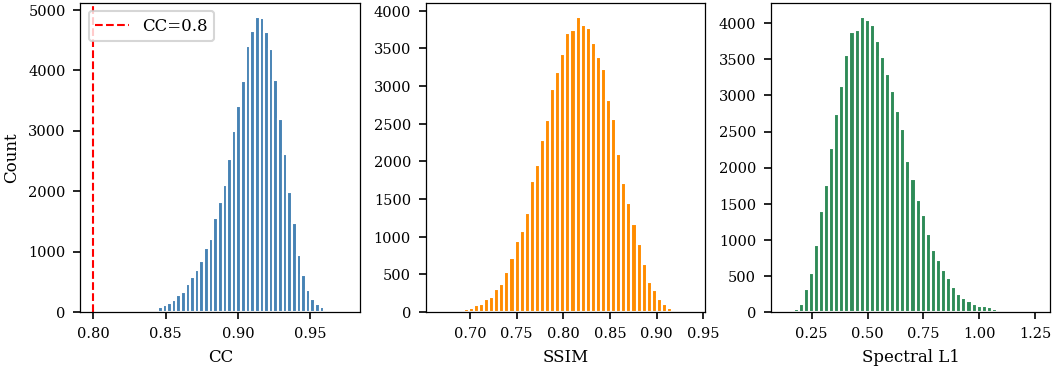

In [16]:
# =========================================================================
# Step 10A - Evaluation Block A: Reconstruction-Quality Metrics
# Synthetic traces are already batch-minmax normalized by WavePhysicsDecoder.
# (CC, SSIM, spectral consistency) - computed over the VALIDATION set
# =========================================================================

apply_ieee_style()

def trace_correlation(pred, target):
    p = pred   - pred.mean(dim=-1, keepdim=True)
    t = target - target.mean(dim=-1, keepdim=True)
    num = (p * t).sum(dim=-1)
    den = torch.sqrt((p**2).sum(dim=-1) * (t**2).sum(dim=-1) + 1e-9)
    return num / den

def trace_ssim_1d(pred, target, win=11):
    from torch.nn.functional import avg_pool1d
    C1, C2 = 0.01**2, 0.03**2
    pad = win // 2
    mu_p = avg_pool1d(pred,        win, stride=1, padding=pad)
    mu_t = avg_pool1d(target,      win, stride=1, padding=pad)
    var_p = avg_pool1d(pred**2,    win, stride=1, padding=pad) - mu_p**2
    var_t = avg_pool1d(target**2,  win, stride=1, padding=pad) - mu_t**2
    cov_pt= avg_pool1d(pred*target,win, stride=1, padding=pad) - mu_p*mu_t
    ssim = ((2*mu_p*mu_t + C1)*(2*cov_pt + C2)) / \
           ((mu_p**2 + mu_t**2 + C1)*(var_p + var_t + C2) + 1e-9)
    return ssim.mean(dim=-1)

def spectral_mismatch(pred, target, dt_ms, nfft=256):
    P = torch.abs(torch.fft.rfft(pred,   n=nfft, dim=-1))
    T = torch.abs(torch.fft.rfft(target, n=nfft, dim=-1))
    spec_l1 = (P - T).abs().mean(dim=-1)
    freqs = torch.fft.rfftfreq(nfft, d=dt_ms/1000).to(pred.device)
    peak_p = freqs[P.mean(dim=0).argmax()]
    peak_t = freqs[T.mean(dim=0).argmax()]
    return spec_l1, (peak_p - peak_t).abs()

# Run over validation set
model.eval()
cc_all, ssim_all, nrms_all, rmse_all = [], [], [], []
spec_dist_all = []
syn_pool, real_pool = [], []

def iter_validation_batches_for_eval():
    if 'val_loader' in globals():
        for (x_batch,) in val_loader:
            yield x_batch.to(DEVICE)
    elif 'iter_batches' in globals() and 'val_idx' in globals():
        for x_batch in iter_batches(val_idx, BATCH_SIZE, shuffle=False):
            yield x_batch
    else:
        raise RuntimeError('No validation iterator found. Run Step 8 before Step 10A.')

with torch.no_grad():
    for x_batch in iter_validation_batches_for_eval():
        phi, syn = model(x_batch)
        T = min(x_batch.shape[1], syn.shape[1])
        x_t, syn_t = x_batch[:, :T], syn[:, :T]
        cc_all  .append(trace_correlation(syn_t, x_t).cpu())
        ssim_all.append(trace_ssim_1d    (syn_t, x_t).cpu())
        nrms_all.append((nrms_loss(syn_t, x_t)).repeat(x_t.shape[0]).cpu())
        rmse_all.append((rmse_loss(syn_t, x_t)).repeat(x_t.shape[0]).cpu())
        sd, _ = spectral_mismatch(syn_t.float(), x_t.float(), dt_ms)
        spec_dist_all.append(sd.cpu())
        if len(real_pool) < 64:
            real_pool.append(x_t[:8].cpu()); syn_pool.append(syn_t[:8].cpu())

cc_v   = torch.cat(cc_all)
ssim_v = torch.cat(ssim_all)
spec_v = torch.cat(spec_dist_all)

val_nrms = float(np.mean([a[0].item() for a in nrms_all]))
val_rmse = float(np.mean([a[0].item() for a in rmse_all]))

print('='*64)
print('Block A - Reconstruction-Quality Metrics')
print('='*64)
print(f'  NRMS         : {val_nrms:.4f}')
print(f'  RMSE         : {val_rmse:.4f}')
print(f'  CC   mean    : {cc_v.mean():.4f}   median: {cc_v.median():.4f}')
print(f'       P10/P90 : {cc_v.quantile(0.10):.4f} / {cc_v.quantile(0.90):.4f}')
print(f'       CC>0.8  : {(cc_v>0.8).float().mean():.1%}   CC>0.9: {(cc_v>0.9).float().mean():.1%}')
print(f'  SSIM mean    : {ssim_v.mean():.4f}')
print(f'  Spec L1      : {spec_v.mean():.4f}')
print('='*64)

fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.6))

axes[0].hist(cc_v.numpy(), bins=50, color='steelblue', edgecolor='white')
axes[0].axvline(0.8, color='r', ls='--', lw=1, label='CC=0.8')
axes[0].set_xlabel('CC'); axes[0].set_ylabel('Count')
axes[0].legend(fontsize=8)

axes[1].hist(ssim_v.numpy(), bins=50, color='darkorange', edgecolor='white')
axes[1].set_xlabel('SSIM')

axes[2].hist(spec_v.numpy(), bins=50, color='seagreen', edgecolor='white')
axes[2].set_xlabel('Spectral L1')

plt.tight_layout(pad=0.8)
save_ieee_figure(fig, 'evaluation_blockA.png')
plt.show()


### Step 10B — Block B: Representation-Quality Diagnostics

Latent-space diagnostics for encoder feature quality and spatial organization.


Block B - Representation-Quality Diagnostics
  Feature dim            : 480
  Effective rank         : 29.77 (ratio 6.2% of dim)
    -> WARNING: possible feature collapse/redundancy
  Mean variance          : 0.0021
  Spectral entropy       : 3.3937
  k-NN physical dist     : 520.29 traces
  Random-neighbour dist  : 778.59 +/- 3.16 traces
  Spatial-neighbour dist : 24.66 traces
  Normalized k-NN dist   : 0.223 of survey L1 span
  Improvement vs random  : 33.2%
    -> CAUTION: feature neighbours have moderate spatial organization
Saved figure: /root/autodl-tmp/rw_pinn_output/evaluation_blockB.png


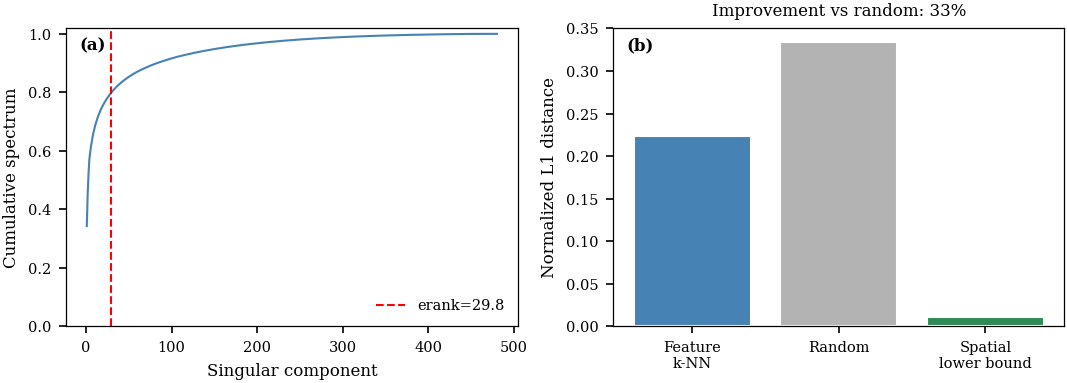

In [17]:
# =========================================================================
# Step 10B - Evaluation Block B: Representation-Quality Diagnostics
# (effective rank, feature-space k-NN, random/spatial baselines)
# =========================================================================

apply_ieee_style()

def extract_features(model, x, n_layers=4):
    """Global-average-pool outputs of the first n encoder conv blocks."""
    enc = model.encoder if hasattr(model, 'encoder') else model._orig_mod.encoder
    h = x.unsqueeze(1)
    feats = []
    blocks = list(enc.convs)
    for layer in blocks[:n_layers]:
        h = layer(h)
        feats.append(h.mean(dim=-1))
    return torch.cat(feats, dim=-1)

def feature_quality(features):
    """Effective rank = exp(spectral entropy). Higher means less collapse."""
    feat = features - features.mean(dim=0)
    s = torch.linalg.svdvals(feat.double())
    p = s / (s.sum() + 1e-9)
    entropy = -(p * torch.log(p + 1e-9)).sum()
    return {
        'variance': feat.var(dim=0).mean().item(),
        'effective_rank': torch.exp(entropy).item(),
        'spectral_entropy': entropy.item(),
        'feat_dim': features.shape[1],
        'singular_values': s.cpu().numpy(),
    }

def coords_to_xy(locs):
    return np.asarray([(c[0], c[1]) for c in locs], dtype=np.float32)

def mean_l1_neighbor_distance(xy, nbr):
    return np.abs(xy[nbr[:, 1:]] - xy[:, None, :]).sum(axis=-1).mean()

def random_neighbor_distance(xy, n_neighbors=6, n_trials=5):
    rng = np.random.default_rng(SEED)
    vals = []
    n = len(xy)
    for _ in range(n_trials):
        nbr = np.empty((n, n_neighbors), dtype=np.int64)
        nbr[:, 0] = np.arange(n)
        for k in range(n):
            pool = rng.choice(n - 1, size=n_neighbors - 1, replace=False)
            pool = np.where(pool >= k, pool + 1, pool)
            nbr[k, 1:] = pool
        vals.append(mean_l1_neighbor_distance(xy, nbr))
    return float(np.mean(vals)), float(np.std(vals))

# Sample a subset for tractable SVD + k-NN diagnostics.
n_sub = min(3000, N_traces)
sub_idx = np.random.choice(N_traces, n_sub, replace=False)
x_sub = torch.tensor(traces_win[sub_idx], dtype=torch.float32, device=DEVICE)

model.eval()
with torch.no_grad():
    feats = extract_features(model, x_sub).cpu().numpy()

fq = feature_quality(torch.tensor(feats))
rank_ratio = fq['effective_rank'] / fq['feat_dim']

print('='*64)
print('Block B - Representation-Quality Diagnostics')
print('='*64)
print(f'  Feature dim            : {fq["feat_dim"]}')
print(f'  Effective rank         : {fq["effective_rank"]:.2f} '
      f'(ratio {rank_ratio:.1%} of dim)')
if rank_ratio > 0.30:
    rank_note = 'OK: features are broadly utilised'
elif rank_ratio > 0.15:
    rank_note = 'CAUTION: moderate feature redundancy'
else:
    rank_note = 'WARNING: possible feature collapse/redundancy'
print(f'    -> {rank_note}')
print(f'  Mean variance          : {fq["variance"]:.4f}')
print(f'  Spectral entropy       : {fq["spectral_entropy"]:.4f}')

knn_stats = None
try:
    from sklearn.neighbors import NearestNeighbors

    xy = coords_to_xy(coords)[sub_idx]
    survey_l1_span = np.ptp(xy, axis=0).sum() + 1e-9

    feat_nn = NearestNeighbors(n_neighbors=6).fit(feats)
    _, feat_nbr = feat_nn.kneighbors(feats)
    feat_dist = float(mean_l1_neighbor_distance(xy, feat_nbr))

    spatial_nn = NearestNeighbors(n_neighbors=6).fit(xy)
    _, spatial_nbr = spatial_nn.kneighbors(xy)
    spatial_dist = float(mean_l1_neighbor_distance(xy, spatial_nbr))

    random_dist, random_std = random_neighbor_distance(xy, n_neighbors=6, n_trials=5)
    feat_norm = feat_dist / survey_l1_span
    random_norm = random_dist / survey_l1_span
    spatial_norm = spatial_dist / survey_l1_span
    improvement = 1.0 - feat_dist / (random_dist + 1e-9)

    knn_stats = {
        'feature': feat_norm,
        'random': random_norm,
        'spatial': spatial_norm,
        'improvement': improvement,
    }

    print(f'  k-NN physical dist     : {feat_dist:.2f} traces')
    print(f'  Random-neighbour dist  : {random_dist:.2f} +/- {random_std:.2f} traces')
    print(f'  Spatial-neighbour dist : {spatial_dist:.2f} traces')
    print(f'  Normalized k-NN dist   : {feat_norm:.3f} of survey L1 span')
    print(f'  Improvement vs random  : {improvement:.1%}')
    if improvement < 0.20:
        print('    -> WARNING: feature neighbours are only weakly spatially organized')
    elif improvement < 0.50:
        print('    -> CAUTION: feature neighbours have moderate spatial organization')
    else:
        print('    -> OK: feature neighbours are substantially more local than random')
except Exception as e:
    print(f'  [k-NN diagnostics skipped: {e}]')

print('='*64)

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.6), constrained_layout=True)

s = fq['singular_values']
energy = np.cumsum(s) / (s.sum() + 1e-9)
axes[0].plot(np.arange(1, len(energy) + 1), energy, color='steelblue', lw=1.0)
axes[0].axvline(fq['effective_rank'], color='r', ls='--', lw=1.0,
                label=f'erank={fq["effective_rank"]:.1f}')
axes[0].set_xlabel('Singular component')
axes[0].set_ylabel('Cumulative spectrum')
axes[0].set_ylim(0, 1.02)
axes[0].legend(frameon=False)
axes[0].text(0.03, 0.97, '(a)', transform=axes[0].transAxes,
             fontsize=8, fontweight='bold', va='top')

if knn_stats is not None:
    labels = ['Feature\nk-NN', 'Random', 'Spatial\nlower bound']
    vals = [knn_stats['feature'], knn_stats['random'], knn_stats['spatial']]
    colors = ['steelblue', '0.70', 'seagreen']
    axes[1].bar(labels, vals, color=colors, edgecolor='white')
    axes[1].set_ylabel('Normalized L1 distance')
    axes[1].set_title(f'Improvement vs random: {knn_stats["improvement"]:.0%}')
else:
    axes[1].axis('off')
    axes[1].text(0.5, 0.5, 'k-NN diagnostics unavailable',
                 ha='center', va='center', transform=axes[1].transAxes)
axes[1].text(0.03, 0.97, '(b)', transform=axes[1].transAxes,
             fontsize=8, fontweight='bold', va='top')

save_ieee_figure(fig, 'evaluation_blockB.png')
plt.show()


## Step 11 — 3D Porosity Volume Prediction

This step assembles the trained encoder output into a 3D porosity volume. It must
be run before **Step 12A / Block C**, because the physical-consistency diagnostics
need `porosity_vol`.


In [18]:

# ==========================================================================
# Step 11: 3D Porosity Volume Prediction
# Run before Step 12A / Block C so lateral-continuity metrics are available.
# RTX 4090 memory-aware version: larger inference batches and float16 volume storage.
# ==========================================================================

def predict_3d_porosity(model, traces, locs, cube_shape, batch_size=INFERENCE_BATCH_SIZE):
    """Run encoder inference in batches and assemble a full 3D porosity volume."""
    n_il, n_xl, n_t = cube_shape
    por_vol = np.full((n_il, n_xl, n_t), np.nan, dtype=VOLUME_DTYPE)

    model.eval()
    with torch.no_grad():
        for start in tqdm(range(0, len(traces), batch_size),
                          desc='3D porosity inference'):
            stop = min(start + batch_size, len(traces))
            chunk_np = np.ascontiguousarray(traces[start:stop])
            chunk = torch.from_numpy(chunk_np).float().to(DEVICE, non_blocking=False)
            phi_batch = model.encode(chunk).detach().cpu().numpy().astype(VOLUME_DTYPE, copy=False)
            del chunk

            for local_k, loc in enumerate(locs[start:stop]):
                phi = phi_batch[local_k]
                if len(loc) == 4:
                    i, j, ts, te = loc
                    fill_len = min(len(phi), te - ts)
                    por_vol[i, j, ts:ts + fill_len] = phi[:fill_len]
                else:
                    i, j = loc[:2]
                    fill_len = min(len(phi), n_t)
                    por_vol[i, j, :fill_len] = phi[:fill_len]

            if DEVICE == 'cuda' and (start // batch_size) % 20 == 0:
                torch.cuda.empty_cache()

    return por_vol

print('Starting 3D porosity volume prediction...')
if DEVICE == 'cuda':
    torch.cuda.empty_cache()
gc.collect()

porosity_vol = predict_3d_porosity(
    model, traces_win, coords, cube.shape, batch_size=INFERENCE_BATCH_SIZE
)

valid_phi = porosity_vol[np.isfinite(porosity_vol)].astype(np.float32, copy=False)
coverage = 100.0 * valid_phi.size / porosity_vol.size
print(f'3D volume shape: {porosity_vol.shape}  dtype={porosity_vol.dtype}')
print(f'Valid voxels: {valid_phi.size:,}/{porosity_vol.size:,} ({coverage:.1f}%)')
print(f'Porosity stats: mean={valid_phi.mean():.3f}  '
      f'std={valid_phi.std():.3f}  '
      f'range=[{valid_phi.min():.3f}, {valid_phi.max():.3f}]')

np.save(OUTPUT_DIR / 'porosity_3d.npy', porosity_vol)
print(f'Saved -> {OUTPUT_DIR / "porosity_3d.npy"}')


Starting 3D porosity volume prediction...


3D porosity inference:   0%|          | 0/2643 [00:00<?, ?it/s]

3D volume shape: (1261, 1073, 716)  dtype=float16
Valid voxels: 968,785,948/968,785,948 (100.0%)
Porosity stats: mean=0.202  std=0.047  range=[0.056, 0.348]
Saved -> /root/autodl-tmp/rw_pinn_output/porosity_3d.npy


## Step 12 — Evaluation Part II: Volume-Level Physical Consistency and Robustness

These diagnostics depend on the trained model, and Block C additionally depends on
the 3D porosity volume from **Step 11**.

### Step 12A — Block C: Physical-Consistency Metrics

Porosity range, Wyllie-derived Vp/density range, and spatial consistency diagnostics.


Block C - Physical-Consistency Metrics
  C1 Porosity in [0.05,0.35] : 100.00%
  C2 Vp in [2.5,5.0] km/s        : 100.00%
     Vp range                    : [2.85, 4.78] km/s
     Density range               : [2090, 2559] kg/m3
  C3 Porosity mean/std/skew      : 0.202 / 0.047 / 0.186
  C4 Lateral gradient corr       : 0.185 (inline=0.181, xline=0.190)
  C5 Vertical abs. diff          : 0.0104 mean, 0.0229 P90
  Note: C4/C5 are sampled spatial diagnostics to avoid OOM on AutoDL.
Saved figure: /root/autodl-tmp/rw_pinn_output/evaluation_blockC.png


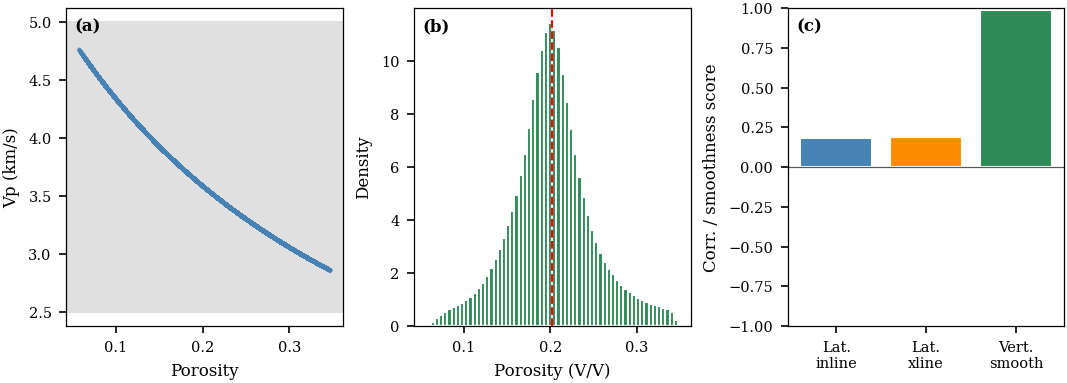

In [19]:

# =========================================================================
# Step 12A - Evaluation Block C: Physical-Consistency Metrics
# Run this after Step 11 so C4/C5 use the predicted 3D porosity volume.
# RTX 4090 memory-aware version: samples gradients instead of materializing full np.diff volumes.
# =========================================================================

apply_ieee_style()

def finite_corr(a, b):
    mask = np.isfinite(a) & np.isfinite(b)
    if mask.sum() <= 100:
        return np.nan
    aa = a[mask].astype(np.float32, copy=False).ravel()
    bb = b[mask].astype(np.float32, copy=False).ravel()
    if aa.std() < 1e-12 or bb.std() < 1e-12:
        return np.nan
    return float(np.corrcoef(aa, bb)[0, 1])

def sampled_physical_volume_metrics(por_vol, seis_cube, n_samples=200_000, seed=SEED):
    """Spatial diagnostics using sampled gradients to avoid multi-GB temporary arrays."""
    metrics = {}
    if por_vol is None or np.all(~np.isfinite(por_vol)):
        return metrics

    rng = np.random.default_rng(seed)
    n_il, n_xl, n_t = por_vol.shape

    i = rng.integers(0, max(n_il - 1, 1), size=n_samples)
    j = rng.integers(0, n_xl, size=n_samples)
    k = rng.integers(0, n_t, size=n_samples)
    pg_il = np.abs(por_vol[i + 1, j, k].astype(np.float32) - por_vol[i, j, k].astype(np.float32))
    sg_il = np.abs(seis_cube[i + 1, j, k].astype(np.float32) - seis_cube[i, j, k].astype(np.float32))

    i = rng.integers(0, n_il, size=n_samples)
    j = rng.integers(0, max(n_xl - 1, 1), size=n_samples)
    k = rng.integers(0, n_t, size=n_samples)
    pg_xl = np.abs(por_vol[i, j + 1, k].astype(np.float32) - por_vol[i, j, k].astype(np.float32))
    sg_xl = np.abs(seis_cube[i, j + 1, k].astype(np.float32) - seis_cube[i, j, k].astype(np.float32))

    metrics['lat_corr_inline'] = finite_corr(pg_il, sg_il)
    metrics['lat_corr_xline'] = finite_corr(pg_xl, sg_xl)
    lateral_vals = [metrics['lat_corr_inline'], metrics['lat_corr_xline']]
    lateral_vals = [v for v in lateral_vals if np.isfinite(v)]
    metrics['lat_corr_mean'] = float(np.mean(lateral_vals)) if lateral_vals else np.nan

    i = rng.integers(0, n_il, size=n_samples)
    j = rng.integers(0, n_xl, size=n_samples)
    k = rng.integers(0, max(n_t - 1, 1), size=n_samples)
    vdiff = np.abs(por_vol[i, j, k + 1].astype(np.float32) - por_vol[i, j, k].astype(np.float32))
    vdiff = vdiff[np.isfinite(vdiff)]
    if vdiff.size:
        metrics['vertical_abs_diff_mean'] = float(np.mean(vdiff))
        metrics['vertical_abs_diff_p90'] = float(np.percentile(vdiff, 90))
    else:
        metrics['vertical_abs_diff_mean'] = np.nan
        metrics['vertical_abs_diff_p90'] = np.nan

    return metrics

n_sub = min(5000, N_traces)
sub_idx = np.random.choice(N_traces, n_sub, replace=False)
x_sub = torch.from_numpy(np.ascontiguousarray(traces_win[sub_idx])).float().to(DEVICE)

model.eval()
with torch.no_grad():
    phi_sub = model.encode(x_sub).cpu().numpy().ravel()
del x_sub
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

in_range = ((phi_sub >= PHI_MIN) & (phi_sub <= PHI_MAX)).mean()

inv_vp = phi_sub / VF + (1.0 - phi_sub) / VM
vp_sub = 1.0 / inv_vp
rho_sub = (1.0 - phi_sub) * RHO_M + phi_sub * RHO_F
vp_ok = ((vp_sub >= 2500) & (vp_sub <= 5000)).mean()

phi_mean, phi_std = phi_sub.mean(), phi_sub.std()
phi_skew = float(pd.Series(phi_sub).skew())

vol_metrics = {}
if 'porosity_vol' in globals():
    vol_metrics = sampled_physical_volume_metrics(porosity_vol, cube)

lat_mean = vol_metrics.get('lat_corr_mean', np.nan)
lat_il = vol_metrics.get('lat_corr_inline', np.nan)
lat_xl = vol_metrics.get('lat_corr_xline', np.nan)
vert_mean = vol_metrics.get('vertical_abs_diff_mean', np.nan)
vert_p90 = vol_metrics.get('vertical_abs_diff_p90', np.nan)

lat_corr_str = (
    f'{lat_mean:.3f} (inline={lat_il:.3f}, xline={lat_xl:.3f})'
    if np.isfinite(lat_mean) else 'n/a (run Step 10 first or insufficient finite sampled voxels)'
)
vert_str = (
    f'{vert_mean:.4f} mean, {vert_p90:.4f} P90'
    if np.isfinite(vert_mean) else 'n/a'
)

print('='*64)
print('Block C - Physical-Consistency Metrics')
print('='*64)
print(f'  C1 Porosity in [{PHI_MIN:.2f},{PHI_MAX:.2f}] : {in_range:.2%}')
print(f'  C2 Vp in [2.5,5.0] km/s        : {vp_ok:.2%}')
print(f'     Vp range                    : [{vp_sub.min()/1e3:.2f}, {vp_sub.max()/1e3:.2f}] km/s')
print(f'     Density range               : [{rho_sub.min():.0f}, {rho_sub.max():.0f}] kg/m3')
print(f'  C3 Porosity mean/std/skew      : {phi_mean:.3f} / {phi_std:.3f} / {phi_skew:.3f}')
print(f'  C4 Lateral gradient corr       : {lat_corr_str}')
print(f'  C5 Vertical abs. diff          : {vert_str}')
print('  Note: C4/C5 are sampled spatial diagnostics to avoid OOM on AutoDL.')
print('='*64)

fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.6), constrained_layout=True)

axes[0].scatter(phi_sub[::8], vp_sub[::8] / 1e3, s=4, alpha=0.30,
                c='steelblue', edgecolors='none')
axes[0].axhspan(2.5, 5.0, color='0.88', zorder=0)
axes[0].set_xlabel('Porosity')
axes[0].set_ylabel('Vp (km/s)')
axes[0].text(0.03, 0.97, '(a)', transform=axes[0].transAxes,
             fontsize=8, fontweight='bold', va='top')

axes[1].hist(phi_sub, bins=60, color='seagreen', edgecolor='white', density=True)
axes[1].axvline(phi_mean, color='r', ls='--', lw=1.0)
axes[1].set_xlabel('Porosity (V/V)')
axes[1].set_ylabel('Density')
axes[1].text(0.03, 0.97, '(b)', transform=axes[1].transAxes,
             fontsize=8, fontweight='bold', va='top')

if np.isfinite(lat_il) or np.isfinite(lat_xl) or np.isfinite(vert_mean):
    labels = ['Lat.\ninline', 'Lat.\nxline', 'Vert.\nsmooth']
    vals = [
        lat_il if np.isfinite(lat_il) else 0.0,
        lat_xl if np.isfinite(lat_xl) else 0.0,
        1.0 / (1.0 + vert_mean) if np.isfinite(vert_mean) else 0.0,
    ]
    axes[2].bar(labels, vals, color=['steelblue', 'darkorange', 'seagreen'],
                edgecolor='white')
    axes[2].axhline(0.0, color='0.35', lw=0.6)
    axes[2].set_ylabel('Corr. / smoothness score')
    axes[2].set_ylim(-1.0, 1.0)
else:
    axes[2].axis('off')
    axes[2].text(0.5, 0.5, 'Run Step 11 before Step 12A\nto compute C4/C5',
                 ha='center', va='center', transform=axes[2].transAxes)
axes[2].text(0.03, 0.97, '(c)', transform=axes[2].transAxes,
             fontsize=8, fontweight='bold', va='top')

save_ieee_figure(fig, 'evaluation_blockC.png')
plt.show()


### Step 12B — Block D: Generalization and Robustness Metrics

Noise response and MC-dropout uncertainty diagnostics for the self-supervised model.


Block D - Generalization & Robustness Metrics
  D1 Train-val NRMS gap (raw)      : 0.0568
     Dropout-corrected gap         : 0.0811
Saved figure: /root/autodl-tmp/rw_pinn_output/evaluation_blockD.png


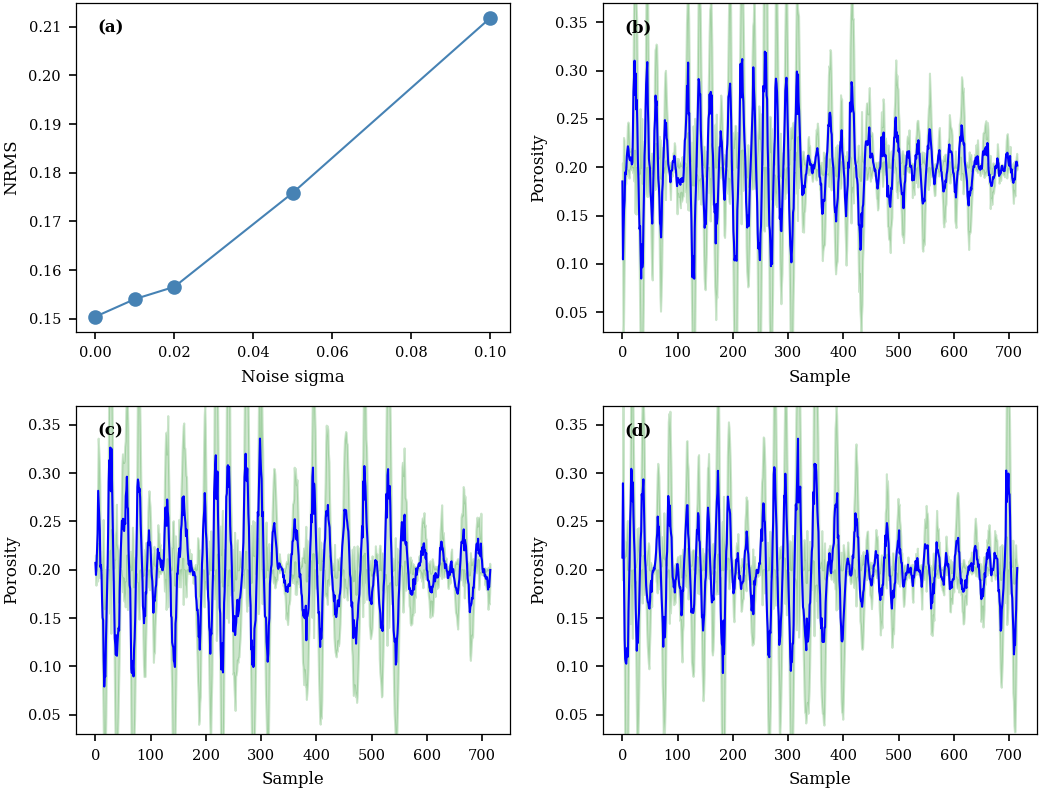

In [20]:
# =========================================================================
# Step 12B - Evaluation Block D: Generalization & Robustness Metrics
# =========================================================================

apply_ieee_style()

train_final = history['train'][-1]
val_final   = history['val'][-1]
raw_gap = abs(train_final - val_final)
dropout_corrected_gap = raw_gap * (1.0 / (1.0 - DROPOUT_RATE))
print('='*64)
print('Block D - Generalization & Robustness Metrics')
print('='*64)
print(f'  D1 Train-val NRMS gap (raw)      : {raw_gap:.4f}')
print(f'     Dropout-corrected gap         : {dropout_corrected_gap:.4f}')

noise_levels = [0.0, 0.01, 0.02, 0.05, 0.10]
noise_nrms = []
n_noise = min(2000, N_traces)
n_idx = np.random.choice(N_traces, n_noise, replace=False)
x_n = torch.tensor(traces_win[n_idx]).to(DEVICE)
model.eval()
with torch.no_grad():
    for sigma in noise_levels:
        x_pert = x_n + torch.randn_like(x_n) * sigma
        x_pert = torch.clamp(x_pert, 0, 1)
        _, syn_n = model(x_pert)
        T = min(x_n.shape[1], syn_n.shape[1])
        nrm = nrms_loss(syn_n[:, :T], x_n[:, :T]).item()
        noise_nrms.append(nrm)

def mc_predict(model, x, n_mc=20):
    model.train()
    preds = []
    with torch.no_grad():
        for _ in range(n_mc):
            preds.append(model.encode(x).cpu().numpy())
    model.eval()
    return np.stack(preds)

n_mc_sub = min(100, N_traces)
sub_idx = np.random.choice(N_traces, n_mc_sub, replace=False)
x_mc = torch.tensor(traces_win[sub_idx[:3]]).to(DEVICE)
mc_samples = mc_predict(model, x_mc, n_mc=20)

fig, axes = plt.subplots(2, 2, figsize=(7.16, 5.5))

ax_noise = axes[0, 0]
ax_noise.plot(noise_levels, noise_nrms, 'o-', lw=1.0, color='steelblue')
ax_noise.set_xlabel('Noise sigma')
ax_noise.set_ylabel('NRMS')
ax_noise.text(0.05, 0.95, '(a)', transform=ax_noise.transAxes,
              fontsize=8, fontweight='bold', va='top')

for idx, (k, ax) in enumerate(zip(range(3),
    [axes[0, 1], axes[1, 0], axes[1, 1]])):
    mean = mc_samples[:, k].mean(axis=0)
    std  = mc_samples[:, k].std(axis=0)
    ts = np.arange(len(mean))
    ax.fill_between(ts, mean - 2*std, mean + 2*std, color='g', alpha=0.2, label='+/-2std')
    ax.plot(ts, mean, 'b', lw=1.0)
    ax.set_xlabel('Sample')
    ax.set_ylabel('Porosity')
    ax.set_ylim(PHI_MIN-0.02, PHI_MAX+0.02)
    ax.text(0.05, 0.95, f'({chr(98+idx)})', transform=ax.transAxes,
            fontsize=8, fontweight='bold', va='top')

plt.tight_layout(pad=1.2)
save_ieee_figure(fig, 'evaluation_blockD.png')
plt.show()


### Step 12 Summary — Recommended Paper-Grade Reporting Checklist

| Category | Must-report | Optional / diagnostic |
|----------|-------------|-----------------------|
| **A. Reconstruction** | NRMS, RMSE, CC mean/median, CC>0.8 or CC>0.9 fraction | SSIM, spectral L1 |
| **B. Representation** | effective-rank ratio, normalized feature k-NN distance, improvement vs random | singular-spectrum plot, spatial lower-bound comparison |
| **C. Physical consistency** | porosity mean/std/skew, Vp and density ranges, C4 lateral gradient correlation, C5 vertical smoothness | section/map overlays after Step 13 |
| **D. Robustness** | noise-response NRMS slope, MC-dropout uncertainty mean/P90 | uncertainty trace examples |

Suggested reporting:

- Use **Step 10A** metrics as the main self-supervised reconstruction evidence.
- Use **Step 10B** to show the latent representation is not collapsed.
- Use **Step 12A** after **Step 11**, because C4/C5 require `porosity_vol`.
- Use **Step 12B** as robustness support rather than the main performance claim.


## Step 13 — 3D Porosity Volume Visualization

The original dense 2x3 summary is split into two IEEE-style double-column figures so
the spatial sections, map, seismic overlay, histogram, and depth trend remain readable.


Saved figure: /root/autodl-tmp/rw_pinn_output/porosity_sections_ieee.png


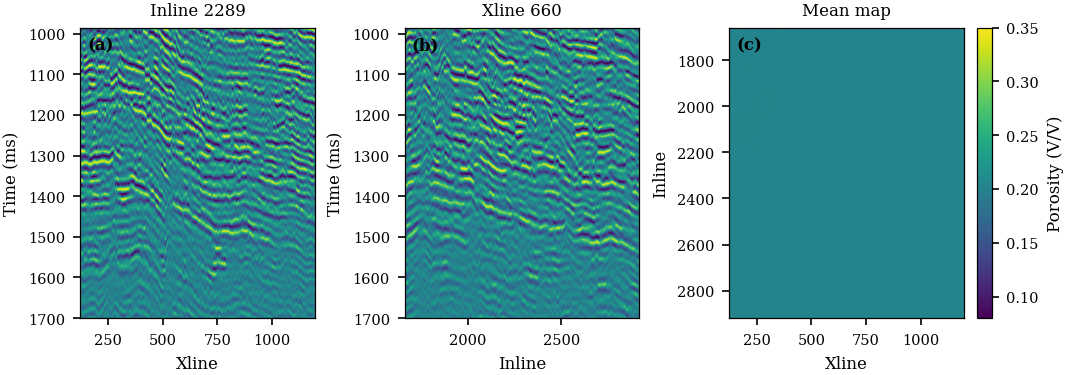

Depth-trend diagnostic:
  finite porosity voxels      : 968,785,948
  bounded porosity voxels     : 968,785,948
  global bounded range        : [0.056, 0.348]
  max valid samples/depth     : 1,353,053 (100.0% of traces)
  min samples/depth for trend : 1,353
  well-sampled time range     : 985.0-1700.0 ms
Saved figure: /root/autodl-tmp/rw_pinn_output/porosity_qc_statistics_ieee.png


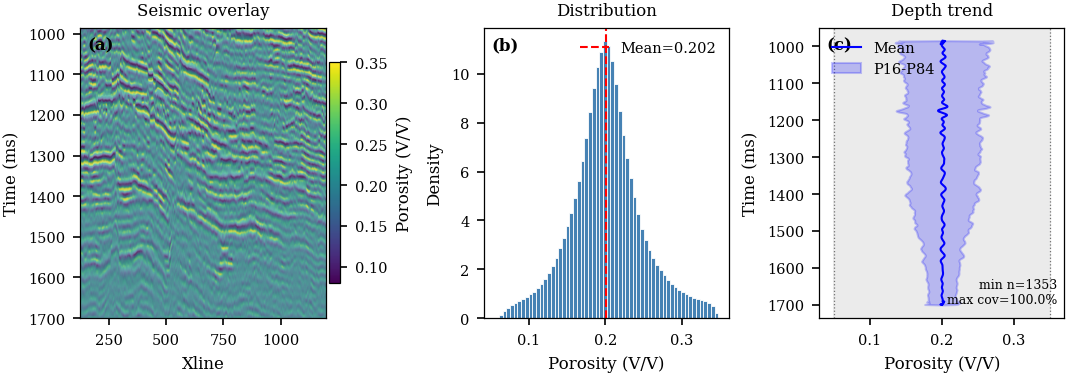

In [21]:
# ========================================================================
# Step 13: 3D Porosity Volume Visualization (Self-Supervised)
# IEEE output: split dense 2x3 overview into two readable paper figures.
# ========================================================================

apply_ieee_style()

if 'porosity_vol' not in globals():
    raise RuntimeError('Run Step 11: 3D Porosity Volume Prediction before Step 13.')

cmap_por = 'viridis'
vmin_p, vmax_p = 0.08, 0.35

por_il = porosity_vol[mid_il, :, :]
por_xl = porosity_vol[:, mid_xl, :]
with np.errstate(all='ignore'):
    por_map = np.nanmean(porosity_vol, axis=2)

# Figure 1: spatial sections and map. Use one shared porosity colorbar so
# the three panels remain comparable without consuming each panel's width.
fig_sec, axes = plt.subplots(1, 3, figsize=(7.16, 2.55), constrained_layout=True)

im0 = axes[0].imshow(
    por_il.T, aspect='auto', cmap=cmap_por, vmin=vmin_p, vmax=vmax_p,
    extent=[xlines[0], xlines[-1], t_axis[-1], t_axis[0]]
)
axes[0].set_title(f'Inline {inlines[mid_il]}')
axes[0].set_xlabel('Xline')
axes[0].set_ylabel('Time (ms)')
axes[0].text(0.03, 0.97, '(a)', transform=axes[0].transAxes,
             fontsize=8, fontweight='bold', va='top')

axes[1].imshow(
    por_xl.T, aspect='auto', cmap=cmap_por, vmin=vmin_p, vmax=vmax_p,
    extent=[inlines[0], inlines[-1], t_axis[-1], t_axis[0]]
)
axes[1].set_title(f'Xline {xlines[mid_xl]}')
axes[1].set_xlabel('Inline')
axes[1].set_ylabel('Time (ms)')
axes[1].text(0.03, 0.97, '(b)', transform=axes[1].transAxes,
             fontsize=8, fontweight='bold', va='top')

axes[2].imshow(
    por_map, aspect='auto', cmap=cmap_por, vmin=vmin_p, vmax=vmax_p,
    extent=[xlines[0], xlines[-1], inlines[-1], inlines[0]]
)
axes[2].set_title('Mean map')
axes[2].set_xlabel('Xline')
axes[2].set_ylabel('Inline')
axes[2].text(0.03, 0.97, '(c)', transform=axes[2].transAxes,
             fontsize=8, fontweight='bold', va='top')

cbar = fig_sec.colorbar(im0, ax=axes, fraction=0.025, pad=0.015)
cbar.set_label('Porosity (V/V)')
save_ieee_figure(fig_sec, 'porosity_sections_ieee.png')
plt.show()

# Figure 2: QC and statistical interpretation. This preserves the information
# from the original lower row without shrinking it into unreadable panels.
fig_qc, axes = plt.subplots(1, 3, figsize=(7.16, 2.55), constrained_layout=True)

seis_il = cube[mid_il, :, :]
vmax_s = np.nanpercentile(np.abs(seis_il), 98)
axes[0].imshow(
    seis_il.T, aspect='auto', cmap='gray', vmin=-vmax_s, vmax=vmax_s,
    extent=[xlines[0], xlines[-1], t_axis[-1], t_axis[0]], alpha=0.65
)
por_rgba = plt.cm.viridis(
    (np.clip(por_il, vmin_p, vmax_p) - vmin_p) / (vmax_p - vmin_p)
)
por_rgba[..., 3] = np.where(np.isnan(por_il), 0.0, 0.68)
axes[0].imshow(
    por_rgba.transpose(1, 0, 2), aspect='auto',
    extent=[xlines[0], xlines[-1], t_axis[-1], t_axis[0]]
)
axes[0].set_title('Seismic overlay')
axes[0].set_xlabel('Xline')
axes[0].set_ylabel('Time (ms)')
axes[0].text(0.03, 0.97, '(a)', transform=axes[0].transAxes,
             fontsize=8, fontweight='bold', va='top')

valid_phi = porosity_vol[np.isfinite(porosity_vol)].ravel()
if valid_phi.size == 0:
    raise RuntimeError('porosity_vol contains no finite values; check Step 11 output.')
axes[1].hist(valid_phi, bins=60, color='steelblue', edgecolor='white',
             linewidth=0.4, density=True)
axes[1].axvline(valid_phi.mean(), color='r', lw=1.0, ls='--',
                label=f'Mean={valid_phi.mean():.3f}')
axes[1].set_xlabel('Porosity (V/V)')
axes[1].set_ylabel('Density')
axes[1].set_title('Distribution')
axes[1].legend(frameon=False)
axes[1].text(0.03, 0.97, '(b)', transform=axes[1].transAxes,
             fontsize=8, fontweight='bold', va='top')

# Depth trend: compute statistics only from valid predicted porosity values.
# For the window experiment, depth coverage varies strongly with time; plotting
# mean +/- std over sparsely covered depths can visually mimic a prediction
# failure. Use a valid-count mask and a bounded percentile band instead.
phi_depth = porosity_vol.reshape(-1, n_t).astype(np.float32, copy=False)
valid_depth = (
    np.isfinite(phi_depth)
    & (phi_depth >= PHI_MIN - 1e-4)
    & (phi_depth <= PHI_MAX + 1e-4)
)
valid_count_depth = valid_depth.sum(axis=0)
min_depth_count = max(50, int(0.001 * phi_depth.shape[0]))
well_sampled_depth = valid_count_depth >= min_depth_count

phi_depth_masked = np.where(valid_depth, phi_depth, np.nan)
with np.errstate(all='ignore'):
    mean_depth = np.nanmean(phi_depth_masked, axis=0)
    p16_depth = np.nanpercentile(phi_depth_masked, 16, axis=0)
    p84_depth = np.nanpercentile(phi_depth_masked, 84, axis=0)

mean_depth[~well_sampled_depth] = np.nan
p16_depth[~well_sampled_depth] = np.nan
p84_depth[~well_sampled_depth] = np.nan

depth_has_out_of_range = np.isfinite(phi_depth).any() and (
    np.nanmin(phi_depth) < PHI_MIN - 1e-3 or np.nanmax(phi_depth) > PHI_MAX + 1e-3
)
if depth_has_out_of_range:
    print('Warning: porosity_vol contains values outside the model porosity bounds; '
          'check Step 11 volume assembly.')

axes[2].plot(mean_depth, t_axis, color='b', lw=1.0, label='Mean')
axes[2].fill_betweenx(t_axis, p16_depth, p84_depth,
                      alpha=0.22, color='b', label='P16-P84')
axes[2].axvspan(PHI_MIN, PHI_MAX, color='0.92', zorder=0)
axes[2].axvline(PHI_MIN, color='0.45', lw=0.6, ls=':')
axes[2].axvline(PHI_MAX, color='0.45', lw=0.6, ls=':')
axes[2].set_xlim(PHI_MIN - 0.02, PHI_MAX + 0.02)
axes[2].invert_yaxis()
axes[2].set_xlabel('Porosity (V/V)')
axes[2].set_ylabel('Time (ms)')
axes[2].set_title('Depth trend')
axes[2].legend(frameon=False)
max_depth_count = int(np.nanmax(valid_count_depth)) if valid_count_depth.size else 0
coverage_pct = 100.0 * max_depth_count / max(phi_depth.shape[0], 1)
well_times = t_axis[well_sampled_depth]
if well_times.size:
    well_range = f'{well_times[0]:.1f}-{well_times[-1]:.1f} ms'
else:
    well_range = 'none'
print('Depth-trend diagnostic:')
print(f'  finite porosity voxels      : {np.isfinite(phi_depth).sum():,}')
print(f'  bounded porosity voxels     : {valid_depth.sum():,}')
print(f'  global bounded range        : [{np.nanmin(phi_depth_masked):.3f}, {np.nanmax(phi_depth_masked):.3f}]')
print(f'  max valid samples/depth     : {max_depth_count:,} ({coverage_pct:.1f}% of traces)')
print(f'  min samples/depth for trend : {min_depth_count:,}')
print(f'  well-sampled time range     : {well_range}')
axes[2].text(0.97, 0.04,
             f'min n={min_depth_count}\nmax cov={coverage_pct:.1f}%',
             transform=axes[2].transAxes, ha='right', va='bottom',
             fontsize=6)
axes[2].text(0.03, 0.97, '(c)', transform=axes[2].transAxes,
             fontsize=8, fontweight='bold', va='top')

sm = plt.cm.ScalarMappable(
    norm=mcolors.Normalize(vmin=vmin_p, vmax=vmax_p), cmap=cmap_por
)
sm.set_array([])
cbar = fig_qc.colorbar(sm, ax=axes[0], fraction=0.045, pad=0.015)
cbar.set_label('Porosity (V/V)')
save_ieee_figure(fig_qc, 'porosity_qc_statistics_ieee.png')
plt.show()


## Step 14 — Porosity Volume Export to SEG-Y


In [22]:
# ========================================================================
# RW-PINN Porosity Inversion Project
# Purpose: Reservoir porosity prediction using seismic data and PINN
# Framework: PyTorch
# ========================================================================

# export_porosity_segy
def export_porosity_segy(porosity_3d, inlines, xlines, dt_ms,
                          output_path: str, template_path: str = None):
    """
    Write the 3D porosity volume to a SEG-Y file.
    Copies trace headers from template if provided.
    """
    n_il, n_xl, n_t = porosity_3d.shape
    output_path = Path(output_path)

    spec = segyio.spec()
    spec.sorting   = segyio.TraceSortingFormat.INLINE_SORTING
    spec.format    = 1          # 4-byte IBM float
    spec.samples   = np.arange(n_t, dtype=np.float32) * dt_ms
    spec.ilines    = inlines
    spec.xlines    = xlines

    with segyio.create(str(output_path), spec) as dst:
        tr_idx = 0
        for i, il in enumerate(tqdm(inlines, desc='Writing SEG-Y')):
            for j, xl in enumerate(xlines):
                por_trace = porosity_3d[i, j, :].copy()
                por_trace[np.isnan(por_trace)] = 0.0  # fill NaN with 0
                dst.header[tr_idx] = {
                    segyio.TraceField.INLINE_3D:    int(il),
                    segyio.TraceField.CROSSLINE_3D: int(xl),
                }
                dst.trace[tr_idx] = por_trace.astype(np.float32)
                tr_idx += 1

    print(f'Porosity SEG-Y exported → {output_path}')

out_segy = OUTPUT_DIR / 'porosity_rwpinn_horizon.segy'
export_porosity_segy(porosity_vol, inlines, xlines, dt_ms, str(out_segy))
print('\nLoad this file in Petrel / Kingdom / OpendTect for 3D display.')


Writing SEG-Y:   0%|          | 0/1261 [00:00<?, ?it/s]

Porosity SEG-Y exported → /root/autodl-tmp/rw_pinn_output/porosity_rwpinn_horizon.segy

Load this file in Petrel / Kingdom / OpendTect for 3D display.


## Output Files

| File | Description |
|------|-------------|
| `rwpinn_best.pt` | Best validation-loss weights |
| `rwpinn_selfsupervised.pt` | Final model weights |
| `learning_curve.png` / `.pdf` | NRMS and RMSE learning curves |
| `reconstruction_qc.png` / `.pdf` | Real vs batch-minmax synthetic trace comparison |
| `evaluation_blockA.png` / `.pdf` | Reconstruction metric distributions |
| `evaluation_blockB.png` / `.pdf` | Representation diagnostics and k-NN baseline comparison |
| `evaluation_blockC.png` / `.pdf` | Physical consistency and spatial diagnostics |
| `evaluation_blockD.png` / `.pdf` | Noise response and MC-dropout uncertainty |
| `porosity_3d.npy` | 3D porosity volume |
| `porosity_sections_ieee.png` / `.pdf` | Inline section, xline section, and mean porosity map |
| `porosity_qc_statistics_ieee.png` / `.pdf` | Seismic overlay, porosity histogram, and depth trend |
| `porosity_rwpinn_horizon.segy` | Porosity SEG-Y volume |
